# Análisis de Series Temporales — Grupo 4
### Programación Concurrente y Distribuida (1ACC0065) · UPC 2026-20

**Proyecto:** Predicción concurrente del consumo energético urbano (Regresión Lineal sobre *Smart Meters in London*, ODS 11).

Este cuaderno **reproduce la sección 12 del informe del TP** («Análisis de Series Temporales»). Cada tabla y cada figura del informe se genera en una celda de este cuaderno, a partir de los datos y del código en Go. Responde a la sugerencia del docente en la PC2: *«Considerar el uso de Análisis de Series Temporales»*.

| Sección del cuaderno | Sección del informe | Produce |
|---|---|---|
| 1. Entorno y datos | — | Go, hardware y dataset |
| 2. Programa en Go | — | `series/` (secuencial y concurrente) |
| 3. Serie diaria concurrente | 12.a | Tabla de tiempos de agregación |
| 4. Tendencia | 12.b | Tabla de las cuatro mediciones y **Figura 12.1** |
| 5. Estacionalidad | 12.c | **Figura 12.2** |
| 6. Pronóstico | 12.d | Tabla frente a reglas ingenuas y **Figura 12.3** |
| 7. Residuos | 12.e | **Figura 12.4** |
| 8. Walk-forward | 12.f | **Figura 12.5** y tabla de speedup por orden de reparto |
| 9. Comparación de tiempos | 12.g | Tabla de XᵀX, agregación y walk-forward |
| 10. Detector de carreras | — | Evidencia de `go run -race` |
| 11. Cifras del informe | 12.h | Todas las cifras citadas, calculadas desde los CSV |
| 12. Evidencias | — | `evidencias_series.zip` para GitHub |

> **Cómo ejecutarlo:** *Entorno de ejecución → Ejecutar todo*. Tarda unos 15 minutos en Colab gratuito (2 vCPU). Los resultados del modelo no dependen del equipo; los tiempos sí, y por eso la sección 1 registra el hardware.

## ¿Qué es una serie temporal y por qué importa aquí?

Una **serie temporal** es una secuencia de observaciones ordenadas en el tiempo. El dataset no es una tabla de casos independientes: es el consumo diario de **5,559 hogares durante más de dos años**. Eso implica tres propiedades que una regresión común no considera:

| Propiedad | Pregunta | Cómo se estudia aquí |
|---|---|---|
| **Tendencia** | ¿El consumo sube, baja o se mantiene con los años, descontando las temporadas? | Medias móviles de 365 días y comparación de cada hogar consigo mismo |
| **Estacionalidad** | ¿Qué patrones se repiten? | Índice semanal (día de la semana) e índice mensual |
| **Dependencia temporal** | ¿El consumo de hoy depende del de ayer? | Pronóstico respetando el orden del tiempo, autocorrelación de errores y walk-forward |

El modelo de la PC2 predice el consumo del día *t* con `lag_1_kwh` (ayer), `lag_7_kwh` (hace una semana), la media y la desviación de los 7 días previos y variables de calendario. En el lenguaje de series temporales es un **modelo autorregresivo con variables exógenas (ARX)** que pronostica **a un día**. Este cuaderno lo describe y lo evalúa como tal.

Como el curso es de **programación concurrente**, cada análisis se implementa además en versión **secuencial** y **concurrente** en Go, y se mide su **tiempo de ejecución**.

---
# 1. Entorno y datos

## 1.1 Hardware

El speedup máximo posible depende del número de núcleos. Colab gratuito asigna normalmente **2 vCPU**, así que el techo teórico es cercano a 2x. Los tiempos del informe se midieron en un entorno equivalente.

In [1]:
!lscpu | grep -E 'Model name|^CPU\(s\)|Thread\(s\) per core|Core\(s\) per socket'
!free -h | head -2

CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) Processor @ 2.80GHz
Thread(s) per core:                      1
Core(s) per socket:                      2


               total        used        free      shared  buff/cache   available
Mem:           7.8Gi       566Mi       7.2Gi        14Mi       311Mi       7.3Gi


## 1.2 Go

Se instala Go 1.22 desde el sitio oficial (la versión de Ubuntu es antigua). Si ya existe una versión 1.22 o superior, se omite. Solo se usa la **biblioteca estándar**, como exige el enunciado.

In [2]:
import os, subprocess
os.environ['PATH'] = '/usr/local/go/bin:' + os.environ['PATH']
def go_ok():
    try:
        v = subprocess.run(['go', 'version'], capture_output=True, text=True).stdout
        return int(v.split('go1.')[1].split('.')[0]) >= 22
    except Exception:
        return False
if not go_ok():
    !wget -q https://go.dev/dl/go1.22.12.linux-amd64.tar.gz -O /tmp/go.tgz && rm -rf /usr/local/go && tar -C /usr/local -xzf /tmp/go.tgz
!go version

go version go1.24.7 linux/amd64


## 1.3 Dataset

Se usa `lcl_modelo_go.csv.gz`, generado por `cleaning/model_prep.go` en la PC1: 3,285,438 filas hogar-día con las variables del modelo y la columna `dataset_split` (train, validation o test).

La celda busca el archivo en la carpeta de Drive del grupo (`MyDrive/Grupo4_PCD_GO/`). Si no lo encuentra, pide subirlo. Luego lo copia al disco local de Colab, porque leer más de 100 MB directamente desde Drive es lento.

In [3]:
import shutil
from pathlib import Path
DATA = os.environ.get('DATA_PATH', '')          # permite indicar la ruta fuera de Colab
if not DATA:
    try:
        from google.colab import drive, files
        drive.mount('/content/drive')
        en_drive = Path('/content/drive/MyDrive/Grupo4_PCD_GO/lcl_modelo_go.csv.gz')
        if en_drive.exists():
            print('Archivo encontrado en Drive:', en_drive)
            origen = en_drive
        else:
            print('No se encontró en Drive. Suba lcl_modelo_go.csv.gz:')
            subido = files.upload()
            origen = Path('/content') / next(iter(subido))
        shutil.copy(origen, '/content/lcl_modelo_go.csv.gz')
        DATA = '/content/lcl_modelo_go.csv.gz'
    except ImportError:
        DATA = 'lcl_modelo_go.csv.gz'
print('Dataset:', DATA, f'({Path(DATA).stat().st_size / 2**20:.0f} MB)')

Dataset: /home/claude/datos/lcl_modelo_go.csv.gz (107 MB)


Vista rápida de las columnas que usa el análisis:

In [4]:
import pandas as pd, numpy as np
muestra = pd.read_csv(DATA, nrows=5)
muestra[['household_id', 'reading_date', 'dataset_split', 'day_index', 'lag_1_kwh', 'lag_7_kwh',
         'rolling_mean_7_kwh', 'target_daily_kwh_capped']]

,household_id,reading_date,dataset_split,day_index,lag_1_kwh,lag_7_kwh,rolling_mean_7_kwh,target_daily_kwh_capped
0,MAC000002,2012-10-20,train,658,8.431,11.087,10.629000,17.378
1,MAC000002,2012-10-21,train,659,17.378,13.223,11.527714,24.490
2,MAC000002,2012-10-22,train,660,24.490,10.257,13.137286,18.885
3,MAC000002,2012-10-23,train,661,18.885,9.769,14.369857,10.485
4,MAC000002,2012-10-24,train,662,10.485,10.885,14.472143,15.537


---
# 2. Programa en Go: `series/`

Todo el cálculo se hace en Go. Python solo se usa para leer los CSV de resultados y graficar. El programa tiene cuatro modos:

| Modo | Sección del informe | Qué hace |
|---|---|---|
| `-mode tendencia` | 12.a, 12.b, 12.c | Agrega la serie diaria (secuencial y concurrente), calcula tendencia y estacionalidad |
| `-mode pronostico` | 12.d, 12.e | Ajusta con train+validation, pronostica test, compara con reglas ingenuas y diagnostica residuos |
| `-mode walkforward` | 12.f | Reentrena mes a mes y pronostica el mes siguiente (secuencial y concurrente) |
| `-mode benchmark` | 12.f | Speedup del walk-forward con media recortada |

**Decisiones de diseño:**

| Decisión | Motivo |
|---|---|
| Mismas funciones `accumulate` y `solve` que `regresion/` | El modelo es exactamente el de la PC2 |
| Las filas se **ordenan por día** al cargar | La ventana de entrenamiento de cualquier fecha de corte es un prefijo `[0, k)` y el mes a pronosticar es un rango contiguo, así que no se copian datos |
| Versión secuencial y concurrente comparten la función de trabajo | La diferencia de tiempo se debe solo a la concurrencia |
| Las filas descartadas se cuentan | En la PC2 se omitían en silencio |
| Tiempo de CPU en `cpu_unix.go` y `cpu_windows.go` | `regresion/` usa `syscall.Getrusage`, que no compila en Windows |

**Patrón de sincronización** (el mismo verificado en Spin, sección 13 del informe):

```
productor ──► canal jobs ──► worker 1 … worker W   (acumulan en memoria LOCAL, sin compartir)
                                   │
                         mu.Lock() → suma al acumulador global → mu.Unlock()   (1 vez por worker)
                                   │
                         wg.Wait() → resultado final
```

In [5]:
!mkdir -p series resultados_series

In [6]:
%%writefile series/go.mod
module series

go 1.22

Writing series/go.mod


In [7]:
%%writefile series/cpu_unix.go
//go:build !windows

package main

import (
	"syscall"
	"time"
)

// cpuTime devuelve el tiempo de CPU (usuario + sistema) consumido por el proceso.
func cpuTime() time.Duration {
	var ru syscall.Rusage
	if err := syscall.Getrusage(syscall.RUSAGE_SELF, &ru); err != nil {
		return 0
	}
	return time.Duration(ru.Utime.Nano() + ru.Stime.Nano())
}

Writing series/cpu_unix.go


In [8]:
%%writefile series/cpu_windows.go
//go:build windows

package main

import (
	"syscall"
	"time"
)

// cpuTime devuelve el tiempo de CPU (usuario + sistema) consumido por el proceso.
func cpuTime() time.Duration {
	h, err := syscall.GetCurrentProcess()
	if err != nil {
		return 0
	}
	var c, e, k, u syscall.Filetime
	if err := syscall.GetProcessTimes(h, &c, &e, &k, &u); err != nil {
		return 0
	}
	// Filetime se expresa en intervalos de 100 ns.
	ticks := func(f syscall.Filetime) int64 { return int64(f.HighDateTime)<<32 | int64(f.LowDateTime) }
	return time.Duration((ticks(k) + ticks(u)) * 100)
}

Writing series/cpu_windows.go


### `series.go` — carga, regresión, pronóstico, residuos y walk-forward

Las partes principales son:
- **`loadAll`:** lee el CSV, detecta la columna del hogar y ordena por día.
- **`fitPrefix`:** ajusta la regresión con todo lo anterior a una fecha.
- **`pronosticos`:** calcula el pronóstico del modelo ARX y de las tres reglas ingenuas.
- **`acfPorHogar`:** autocorrelación de los residuos y Durbin-Watson.
- **`walkSecuencial` y `walkConcurrente`:** el walk-forward mensual en sus dos versiones.

In [9]:
%%writefile series/series.go
// series.go — Análisis de series temporales del modelo de Regresión Lineal (TP, Grupo 4).
//
// El modelo de la PC2 predice el consumo del día t con rezagos (lag_1, lag_7),
// estadísticas móviles de 7 días y variables de calendario: es un modelo
// autorregresivo con variables exógenas (ARX) a un día de horizonte.
// Este programa lo evalúa como pronóstico:
//
//	-mode pronostico   ajusta con train+validation y pronostica el conjunto test
//	                   (ene–feb 2014); compara con líneas base ingenuas y
//	                   diagnostica los residuos (ACF por hogar y Durbin-Watson).
//	-mode walkforward  validación walk-forward mensual (origen móvil, ventana
//	                   expansiva): un ajuste por mes, repartidos entre un Worker
//	                   Pool. Compara la versión secuencial con la concurrente.
//	-mode benchmark    speedup del walk-forward con media recortada.
//	-mode tendencia    tendencia y estacionalidad de la serie diaria (ver tendencia.go).
//
// Solo biblioteca estándar de Go.
package main

import (
	"bufio"
	"compress/gzip"
	"encoding/csv"
	"flag"
	"fmt"
	"io"
	"math"
	"os"
	"path/filepath"
	"runtime"
	"sort"
	"strconv"
	"strings"
	"sync"
	"time"
)

// Mismas 11 variables que regresion.go (PC2) + intercepto = P = 12 coeficientes.
var featureCols = []string{
	"tariff_tou", "is_weekend", "dow_sin", "dow_cos", "month_sin", "month_cos",
	"day_index", "lag_1_kwh", "lag_7_kwh", "rolling_mean_7_kwh", "rolling_std_7_kwh",
}

const targetCol = "target_daily_kwh_capped"

var P = len(featureCols) + 1

// Posición en cada fila de X de las variables que usan las líneas base (+1 por el intercepto).
var (
	cLag1  = 1 + indexOf(featureCols, "lag_1_kwh")
	cLag7  = 1 + indexOf(featureCols, "lag_7_kwh")
	cMean7 = 1 + indexOf(featureCols, "rolling_mean_7_kwh")
)

// day_index = días transcurridos desde esta fecha (definido en model_prep.go, PC1).
var origen = time.Date(2011, 1, 1, 0, 0, 0, 0, time.UTC)

const (
	splitTrain = iota
	splitValid
	splitTest
)

// Data guarda X en un solo slice contiguo, ORDENADO POR DÍA. Así, la ventana de
// entrenamiento de cualquier origen temporal es un prefijo [0, k) y el mes a
// pronosticar es un rango contiguo [k, k2): se reutiliza accumulate tal cual.
type Data struct {
	N      int
	X      []float64 // N*P, columna 0 = intercepto
	Y      []float64
	Hogar  []int32 // índice del hogar
	Dia    []int32 // day_index
	Split  []uint8
	Hogars []string // id original de cada hogar
}

func indexOf(xs []string, s string) int {
	for i, x := range xs {
		if x == s {
			return i
		}
	}
	panic("columna no encontrada: " + s)
}

func fecha(dia int32) time.Time { return origen.AddDate(0, 0, int(dia)) }

func diaDe(t time.Time) int32 { return int32(t.Sub(origen).Hours() / 24) }

// ---------------------------------------------------------------- carga

func loadAll(path, idCol string) (*Data, error) {
	f, err := os.Open(path)
	if err != nil {
		return nil, err
	}
	defer f.Close()
	var r io.Reader = bufio.NewReaderSize(f, 4<<20)
	if strings.HasSuffix(path, ".gz") {
		gz, err := gzip.NewReader(r)
		if err != nil {
			return nil, err
		}
		defer gz.Close()
		r = gz
	}
	cr := csv.NewReader(bufio.NewReaderSize(r, 4<<20))
	cr.ReuseRecord = true
	header, err := cr.Read()
	if err != nil {
		return nil, err
	}
	idx := map[string]int{}
	for i, h := range header {
		idx[strings.TrimSpace(strings.TrimPrefix(h, "\xef\xbb\xbf"))] = i
	}
	col := func(name string) (int, error) {
		j, ok := idx[name]
		if !ok {
			return 0, fmt.Errorf("falta la columna %q; columnas disponibles: %s", name, strings.Join(header, ", "))
		}
		return j, nil
	}
	// Columna del hogar: la indicada o la primera candidata presente.
	if idCol == "" {
		for _, c := range []string{"LCLid", "lclid", "household_id", "hogar_id", "id"} {
			if _, ok := idx[c]; ok {
				idCol = c
				break
			}
		}
		if idCol == "" {
			return nil, fmt.Errorf("no se encontró la columna del hogar; indíquela con -id. Columnas: %s", strings.Join(header, ", "))
		}
	}
	cols := make([]int, len(featureCols))
	for i, c := range featureCols {
		if cols[i], err = col(c); err != nil {
			return nil, err
		}
	}
	yi, err := col(targetCol)
	if err != nil {
		return nil, err
	}
	si, err := col("dataset_split")
	if err != nil {
		return nil, err
	}
	hi, err := col(idCol)
	if err != nil {
		return nil, err
	}
	di := 1 + indexOf(featureCols, "day_index") // posición de day_index dentro de la fila

	raw := &Data{}
	ids := map[string]int32{}
	row := make([]float64, P)
	descartadas := 0
	for {
		rec, e := cr.Read()
		if e == io.EOF {
			break
		}
		if e != nil {
			return nil, e
		}
		var sp uint8
		switch rec[si] {
		case "train":
			sp = splitTrain
		case "validation":
			sp = splitValid
		case "test":
			sp = splitTest
		default:
			descartadas++
			continue
		}
		row[0] = 1
		ok := true
		for i, j := range cols {
			v, e := strconv.ParseFloat(rec[j], 64)
			if e != nil || math.IsNaN(v) || math.IsInf(v, 0) {
				ok = false
				break
			}
			row[i+1] = v
		}
		y, e := strconv.ParseFloat(rec[yi], 64)
		if !ok || e != nil || math.IsNaN(y) {
			descartadas++ // a diferencia de la PC2, las filas descartadas se cuentan
			continue
		}
		h, existe := ids[rec[hi]]
		if !existe {
			h = int32(len(raw.Hogars))
			ids[rec[hi]] = h
			raw.Hogars = append(raw.Hogars, rec[hi])
		}
		raw.X = append(raw.X, row...)
		raw.Y = append(raw.Y, y)
		raw.Hogar = append(raw.Hogar, h)
		raw.Dia = append(raw.Dia, int32(math.Round(row[di])))
		raw.Split = append(raw.Split, sp)
		raw.N++
	}
	if descartadas > 0 {
		fmt.Printf("Aviso: %d filas descartadas por valores no numéricos o split desconocido\n", descartadas)
	}
	return ordenarPorDia(raw), nil
}

// ordenarPorDia reordena las filas por (día, hogar) con un ordenamiento estable.
func ordenarPorDia(d *Data) *Data {
	perm := make([]int, d.N)
	for i := range perm {
		perm[i] = i
	}
	sort.SliceStable(perm, func(a, b int) bool {
		if d.Dia[perm[a]] != d.Dia[perm[b]] {
			return d.Dia[perm[a]] < d.Dia[perm[b]]
		}
		return d.Hogar[perm[a]] < d.Hogar[perm[b]]
	})
	o := &Data{N: d.N, X: make([]float64, len(d.X)), Y: make([]float64, d.N),
		Hogar: make([]int32, d.N), Dia: make([]int32, d.N), Split: make([]uint8, d.N), Hogars: d.Hogars}
	for i, j := range perm {
		copy(o.X[i*P:i*P+P], d.X[j*P:j*P+P])
		o.Y[i], o.Hogar[i], o.Dia[i], o.Split[i] = d.Y[j], d.Hogar[j], d.Dia[j], d.Split[j]
	}
	return o
}

// primerIndice devuelve la primera fila con Dia >= dia (búsqueda binaria; Data está ordenado).
func primerIndice(d *Data, dia int32) int {
	return sort.Search(d.N, func(i int) bool { return d.Dia[i] >= dia })
}

// ---------------------------------------------------------------- regresión (igual que la PC2)

func accumulate(d *Data, lo, hi int, xtx, xty []float64) {
	for r := lo; r < hi; r++ {
		x := d.X[r*P : r*P+P]
		y := d.Y[r]
		for i := 0; i < P; i++ {
			xi := x[i]
			xty[i] += xi * y
			rowI := xtx[i*P : i*P+P]
			for j := i; j < P; j++ {
				rowI[j] += xi * x[j]
			}
		}
	}
}

func mirror(xtx []float64) {
	for i := 0; i < P; i++ {
		for j := 0; j < i; j++ {
			xtx[i*P+j] = xtx[j*P+i]
		}
	}
}

func solve(A, b []float64) ([]float64, error) {
	n := len(b)
	M := make([]float64, n*(n+1))
	for i := 0; i < n; i++ {
		copy(M[i*(n+1):], A[i*n:i*n+n])
		M[i*(n+1)+n] = b[i]
	}
	for c := 0; c < n; c++ {
		p := c
		for r := c + 1; r < n; r++ {
			if math.Abs(M[r*(n+1)+c]) > math.Abs(M[p*(n+1)+c]) {
				p = r
			}
		}
		if math.Abs(M[p*(n+1)+c]) < 1e-12 {
			return nil, fmt.Errorf("matriz singular en columna %d", c)
		}
		for k := 0; k <= n; k++ {
			M[c*(n+1)+k], M[p*(n+1)+k] = M[p*(n+1)+k], M[c*(n+1)+k]
		}
		for r := c + 1; r < n; r++ {
			f := M[r*(n+1)+c] / M[c*(n+1)+c]
			for k := c; k <= n; k++ {
				M[r*(n+1)+k] -= f * M[c*(n+1)+k]
			}
		}
	}
	beta := make([]float64, n)
	for i := n - 1; i >= 0; i-- {
		s := M[i*(n+1)+n]
		for k := i + 1; k < n; k++ {
			s -= M[i*(n+1)+k] * beta[k]
		}
		beta[i] = s / M[i*(n+1)+i]
	}
	return beta, nil
}

// fitPrefix ajusta la regresión con las filas [0, hi): todo lo anterior al origen.
func fitPrefix(d *Data, hi int) ([]float64, error) {
	xtx, xty := make([]float64, P*P), make([]float64, P)
	accumulate(d, 0, hi, xtx, xty)
	mirror(xtx)
	return solve(xtx, xty)
}

func predict(d *Data, r int, beta []float64) float64 {
	x := d.X[r*P : r*P+P]
	var s float64
	for i := 0; i < P; i++ {
		s += beta[i] * x[i]
	}
	return s
}

// ---------------------------------------------------------------- métricas de pronóstico

type Metr struct {
	N                         int
	SSE, SAE, SSMAPE, SY, SY2 float64
}

func (m *Metr) Add(y, p float64) {
	e := y - p
	m.N++
	m.SSE += e * e
	m.SAE += math.Abs(e)
	if den := math.Abs(y) + math.Abs(p); den > 0 {
		m.SSMAPE += 200 * math.Abs(e) / den
	}
	m.SY += y
	m.SY2 += y * y
}

func (m *Metr) Merge(o Metr) {
	m.N += o.N
	m.SSE += o.SSE
	m.SAE += o.SAE
	m.SSMAPE += o.SSMAPE
	m.SY += o.SY
	m.SY2 += o.SY2
}

func (m Metr) RMSE() float64  { return math.Sqrt(m.SSE / float64(m.N)) }
func (m Metr) MAE() float64   { return m.SAE / float64(m.N) }
func (m Metr) SMAPE() float64 { return m.SSMAPE / float64(m.N) }
func (m Metr) R2() float64 {
	sst := m.SY2 - m.SY*m.SY/float64(m.N)
	return 1 - m.SSE/sst
}

// Predictores: el modelo ARX y tres líneas base ingenuas de series temporales.
var nombres = []string{"ARX (regresión)", "Ingenuo: lag_1 (ayer)", "Ingenuo estacional: lag_7", "Media móvil 7 días"}

func pronosticos(d *Data, r int, beta []float64) [4]float64 {
	x := d.X[r*P : r*P+P]
	return [4]float64{predict(d, r, beta), x[cLag1], x[cLag7], x[cMean7]}
}

// ---------------------------------------------------------------- diagnóstico de residuos

// acfPorHogar calcula la autocorrelación de los residuos para los rezagos 1..maxLag,
// emparejando solo días del MISMO hogar separados exactamente k días. También
// devuelve el estadístico de Durbin-Watson con los pares de días consecutivos.
func acfPorHogar(d *Data, filas []int, res []float64, maxLag int) (acf []float64, pares []int, dw float64) {
	ord := append([]int(nil), filas...)
	sort.Slice(ord, func(a, b int) bool {
		ia, ib := ord[a], ord[b]
		if d.Hogar[ia] != d.Hogar[ib] {
			return d.Hogar[ia] < d.Hogar[ib]
		}
		return d.Dia[ia] < d.Dia[ib]
	})
	var media float64
	for _, i := range ord {
		media += res[i]
	}
	media /= float64(len(ord))
	var den float64
	for _, i := range ord {
		den += (res[i] - media) * (res[i] - media)
	}
	num := make([]float64, maxLag+1)
	pares = make([]int, maxLag+1)
	var dwNum, dwDen float64
	for p, i := range ord {
		ei := res[i] - media
		for q := p - 1; q >= 0; q-- {
			j := ord[q]
			if d.Hogar[j] != d.Hogar[i] {
				break
			}
			k := int(d.Dia[i] - d.Dia[j])
			if k > maxLag {
				break
			}
			num[k] += ei * (res[j] - media)
			pares[k]++
			if k == 1 {
				dwNum += (res[i] - res[j]) * (res[i] - res[j])
				dwDen += res[i] * res[i]
			}
		}
	}
	acf = make([]float64, maxLag+1)
	for k := 1; k <= maxLag; k++ {
		acf[k] = num[k] / den
	}
	if dwDen > 0 {
		dw = dwNum / dwDen
	}
	return
}

// ---------------------------------------------------------------- walk-forward

// Fold: se entrena con las filas [0, Lo) y se pronostica el mes [Lo, Hi).
type Fold struct {
	ID     int
	Mes    string
	Lo, Hi int
}

type FoldRes struct {
	Fold
	Metr [4]Metr // ARX y líneas base
	Err  error
}

func armarFolds(d *Data, desde string) ([]Fold, error) {
	t, err := time.Parse("2006-01", desde)
	if err != nil {
		return nil, fmt.Errorf("-desde debe tener formato AAAA-MM: %v", err)
	}
	ultimo := fecha(d.Dia[d.N-1])
	var folds []Fold
	for m := t; !m.After(ultimo); m = m.AddDate(0, 1, 0) {
		lo, hi := primerIndice(d, diaDe(m)), primerIndice(d, diaDe(m.AddDate(0, 1, 0)))
		if lo > 0 && hi > lo {
			folds = append(folds, Fold{len(folds), m.Format("2006-01"), lo, hi})
		}
	}
	if len(folds) == 0 {
		return nil, fmt.Errorf("no hay meses para evaluar desde %s", desde)
	}
	return folds, nil
}

// runFold es el MISMO trabajo para la versión secuencial y la concurrente.
func runFold(d *Data, f Fold) FoldRes {
	r := FoldRes{Fold: f}
	beta, err := fitPrefix(d, f.Lo)
	if err != nil {
		r.Err = err
		return r
	}
	for i := f.Lo; i < f.Hi; i++ {
		p := pronosticos(d, i, beta)
		for k := range p {
			r.Metr[k].Add(d.Y[i], p[k])
		}
	}
	return r
}

func walkSecuencial(d *Data, folds []Fold) ([]FoldRes, Metr) {
	res := make([]FoldRes, len(folds))
	var global Metr
	for _, f := range folds {
		res[f.ID] = runFold(d, f)
		global.Merge(res[f.ID].Metr[0])
	}
	return res, global
}

// walkConcurrente reparte los meses entre un Worker Pool:
//   - canal jobs: reparto dinámico; un worker libre toma el siguiente mes.
//   - res[f.ID]: cada fold escribe en su propia posición (sin memoria compartida).
//   - global: acumulador compartido de errores, protegido por sync.Mutex
//     (mismo protocolo verificado en Spin: worker_pool.pml).
//   - sync.WaitGroup: espera a todos los workers.
//
// Orden "desc": se envían primero los meses con más filas de entrenamiento
// (los más costosos). Es la heurística LPT (Longest Processing Time first) y
// evita que el fold más pesado empiece al final y deje a los demás workers ociosos.
func walkConcurrente(d *Data, folds []Fold, workers int, orden string) ([]FoldRes, Metr) {
	res := make([]FoldRes, len(folds))
	var global Metr
	var mu sync.Mutex
	var wg sync.WaitGroup
	jobs := make(chan Fold, len(folds))

	envio := append([]Fold(nil), folds...)
	if orden == "desc" {
		sort.Slice(envio, func(a, b int) bool { return envio[a].Lo > envio[b].Lo })
	}
	for w := 0; w < workers; w++ {
		wg.Add(1)
		go func() {
			defer wg.Done()
			for f := range jobs {
				r := runFold(d, f)
				res[f.ID] = r // posición exclusiva del fold
				mu.Lock()     // ---- sección crítica ----
				global.Merge(r.Metr[0])
				mu.Unlock()
			}
		}()
	}
	for _, f := range envio {
		jobs <- f
	}
	close(jobs)
	wg.Wait()
	return res, global
}

// ---------------------------------------------------------------- utilidades

func ms(d time.Duration) float64 { return float64(d.Nanoseconds()) / 1e6 }

func trimmedMean(xs []float64, frac float64) float64 {
	s := append([]float64(nil), xs...)
	sort.Float64s(s)
	k := int(float64(len(s)) * frac)
	s = s[k : len(s)-k]
	var sum float64
	for _, v := range s {
		sum += v
	}
	return sum / float64(len(s))
}

func parseInts(s string) []int {
	var out []int
	for _, p := range strings.Split(s, ",") {
		if v, err := strconv.Atoi(strings.TrimSpace(p)); err == nil && v > 0 {
			out = append(out, v)
		}
	}
	return out
}

func f4(v float64) string { return strconv.FormatFloat(v, 'f', 4, 64) }

func crearCSV(dir, nombre string, cab []string) (*os.File, *csv.Writer) {
	f, err := os.Create(filepath.Join(dir, nombre))
	if err != nil {
		fatal(err)
	}
	w := csv.NewWriter(f)
	w.Write(cab)
	return f, w
}

func fatal(err error) {
	fmt.Fprintln(os.Stderr, "ERROR:", err)
	os.Exit(1)
}

func cerrar(f *os.File, w *csv.Writer) {
	w.Flush()
	if err := w.Error(); err != nil {
		fatal(err)
	}
	f.Close()
}

// ---------------------------------------------------------------- modos

func modoPronostico(d *Data, outdir string, maxLag int) {
	k := primerIndice(d, diaDe(time.Date(2014, 1, 1, 0, 0, 0, 0, time.UTC)))
	for i := k; i < d.N; i++ {
		if d.Split[i] != splitTest {
			fatal(fmt.Errorf("se esperaba que todo lo posterior al 2014-01-01 fuera test"))
		}
	}
	if k == d.N {
		fatal(fmt.Errorf("el dataset no tiene filas de test"))
	}
	beta, err := fitPrefix(d, k)
	if err != nil {
		fatal(err)
	}
	fmt.Printf("\n=== PRONÓSTICO A UN DÍA SOBRE TEST (%s a %s) ===\n",
		fecha(d.Dia[k]).Format("2006-01-02"), fecha(d.Dia[d.N-1]).Format("2006-01-02"))
	fmt.Printf("Ajuste con train+validation: %d filas | Test: %d filas\n\n", k, d.N-k)

	var m [4]Metr
	res := make([]float64, d.N) // residuos del ARX en todas las filas
	for i := 0; i < d.N; i++ {
		p := pronosticos(d, i, beta)
		res[i] = d.Y[i] - p[0]
		if i >= k {
			for j := range p {
				m[j].Add(d.Y[i], p[j])
			}
		}
	}
	f, w := crearCSV(outdir, "pronostico_test.csv",
		[]string{"predictor", "n", "rmse", "mae", "smape_pct", "r2", "mejora_rmse_vs_naive_estacional_pct"})
	fmt.Printf("%-26s %8s %8s %9s %8s %s\n", "Predictor", "RMSE", "MAE", "sMAPE %", "R2", "Mejora RMSE vs lag_7")
	for j := range m {
		mej := 100 * (1 - m[j].RMSE()/m[2].RMSE())
		fmt.Printf("%-26s %8.4f %8.4f %9.2f %8.4f %+.1f %%\n", nombres[j], m[j].RMSE(), m[j].MAE(), m[j].SMAPE(), m[j].R2(), mej)
		w.Write([]string{nombres[j], strconv.Itoa(m[j].N), f4(m[j].RMSE()), f4(m[j].MAE()), f4(m[j].SMAPE()), f4(m[j].R2()), f4(mej)})
	}
	cerrar(f, w)

	// Diagnóstico de residuos: dentro de la muestra (train+validation) y fuera (test).
	f, w = crearCSV(outdir, "acf_residuos.csv", []string{"conjunto", "lag", "acf", "pares", "banda_95"})
	fd, wd := crearCSV(outdir, "diagnostico_residuos.csv", []string{"conjunto", "n", "media_residuo", "durbin_watson", "acf_1", "acf_7", "acf_14"})
	for _, c := range []struct {
		nombre string
		lo, hi int
	}{{"ajuste", 0, k}, {"test", k, d.N}} {
		filas := make([]int, 0, c.hi-c.lo)
		var media float64
		for i := c.lo; i < c.hi; i++ {
			filas = append(filas, i)
			media += res[i]
		}
		media /= float64(len(filas))
		acf, pares, dw := acfPorHogar(d, filas, res, maxLag)
		for l := 1; l <= maxLag; l++ {
			banda := 0.0
			if pares[l] > 0 {
				banda = 1.96 / math.Sqrt(float64(pares[l]))
			}
			w.Write([]string{c.nombre, strconv.Itoa(l), f4(acf[l]), strconv.Itoa(pares[l]), f4(banda)})
		}
		a14 := 0.0
		if maxLag >= 14 {
			a14 = acf[14]
		}
		wd.Write([]string{c.nombre, strconv.Itoa(len(filas)), f4(media), f4(dw), f4(acf[1]), f4(acf[7]), f4(a14)})
		fmt.Printf("\nResiduos [%s] n=%d | media %.4f | Durbin-Watson %.3f | ACF(1) %.3f | ACF(7) %.3f\n",
			c.nombre, len(filas), media, dw, acf[1], acf[7])
	}
	cerrar(f, w)
	cerrar(fd, wd)

	// Muestra para graficar: los 3 hogares con más días en test.
	cuenta := map[int32]int{}
	for i := k; i < d.N; i++ {
		cuenta[d.Hogar[i]]++
	}
	hs := make([]int32, 0, len(cuenta))
	for h := range cuenta {
		hs = append(hs, h)
	}
	sort.Slice(hs, func(a, b int) bool {
		if cuenta[hs[a]] != cuenta[hs[b]] {
			return cuenta[hs[a]] > cuenta[hs[b]]
		}
		return hs[a] < hs[b]
	})
	if len(hs) > 3 {
		hs = hs[:3]
	}
	elegido := map[int32]bool{}
	for _, h := range hs {
		elegido[h] = true
	}
	f, w = crearCSV(outdir, "pronostico_muestra.csv", []string{"hogar", "fecha", "real", "arx", "naive_lag7"})
	for i := k; i < d.N; i++ {
		if elegido[d.Hogar[i]] {
			p := pronosticos(d, i, beta)
			w.Write([]string{d.Hogars[d.Hogar[i]], fecha(d.Dia[i]).Format("2006-01-02"), f4(d.Y[i]), f4(p[0]), f4(p[2])})
		}
	}
	cerrar(f, w)
}

func modoWalkforward(d *Data, outdir, desde string, workers int, orden string) {
	folds, err := armarFolds(d, desde)
	if err != nil {
		fatal(err)
	}
	t0 := time.Now()
	seq, gs := walkSecuencial(d, folds)
	tSeq := time.Since(t0)
	t0 = time.Now()
	conc, gc := walkConcurrente(d, folds, workers, orden)
	tConc := time.Since(t0)

	// La concurrencia no debe alterar los resultados de ningún fold.
	var dif float64
	for i := range seq {
		if seq[i].Err != nil || conc[i].Err != nil {
			fatal(fmt.Errorf("fold %s: %v %v", seq[i].Mes, seq[i].Err, conc[i].Err))
		}
		dif = math.Max(dif, math.Abs(seq[i].Metr[0].SSE-conc[i].Metr[0].SSE))
	}
	fmt.Printf("\n=== WALK-FORWARD MENSUAL (%d meses, desde %s) ===\n", len(folds), desde)
	fmt.Printf("Secuencial: %.1f ms | Concurrente (%d workers, orden %s): %.1f ms | speedup %.2fx\n",
		ms(tSeq), workers, orden, ms(tConc), ms(tSeq)/ms(tConc))
	fmt.Printf("Diferencia máxima de SSE entre versiones: %.2e | RMSE global sec %.4f / conc %.4f\n\n",
		dif, gs.RMSE(), gc.RMSE())

	f, w := crearCSV(outdir, "walkforward_meses.csv",
		[]string{"mes", "filas_entrenamiento", "filas_mes", "rmse_arx", "rmse_naive_lag1", "rmse_naive_lag7", "rmse_media7", "mae_arx", "smape_arx", "r2_arx"})
	fmt.Printf("%-8s %12s %9s %9s %9s %9s\n", "Mes", "Entrenam.", "Filas", "RMSE ARX", "RMSE lag7", "R2 ARX")
	for _, r := range seq {
		m := r.Metr
		fmt.Printf("%-8s %12d %9d %9.4f %9.4f %9.4f\n", r.Mes, r.Lo, r.Hi-r.Lo, m[0].RMSE(), m[2].RMSE(), m[0].R2())
		w.Write([]string{r.Mes, strconv.Itoa(r.Lo), strconv.Itoa(r.Hi - r.Lo), f4(m[0].RMSE()), f4(m[1].RMSE()),
			f4(m[2].RMSE()), f4(m[3].RMSE()), f4(m[0].MAE()), f4(m[0].SMAPE()), f4(m[0].R2())})
	}
	cerrar(f, w)
}

func modoBenchmark(d *Data, outdir, desde string, reps int, wlist []int, orden string) {
	folds, err := armarFolds(d, desde)
	if err != nil {
		fatal(err)
	}
	f, w := crearCSV(outdir, "walkforward_benchmark_"+orden+".csv", []string{"modo", "workers", "orden", "rep", "wall_ms", "cpu_ms", "alloc_kb", "gc"})
	configs := append([]int{0}, wlist...)
	fmt.Printf("\n=== BENCHMARK WALK-FORWARD (%d meses, %d repeticiones + 1 de calentamiento) ===\n", len(folds), reps)
	for _, nw := range configs {
		modo := "secuencial"
		if nw > 0 {
			modo = "concurrente"
		}
		ejecutar := func() {
			if nw == 0 {
				walkSecuencial(d, folds)
			} else {
				walkConcurrente(d, folds, nw, orden)
			}
		}
		ejecutar() // calentamiento, no se registra
		walls := make([]float64, 0, reps)
		for r := 1; r <= reps; r++ {
			var m0, m1 runtime.MemStats
			runtime.GC()
			runtime.ReadMemStats(&m0)
			c0, t0 := cpuTime(), time.Now()
			ejecutar()
			wall, cpu := time.Since(t0), cpuTime()-c0
			runtime.ReadMemStats(&m1)
			walls = append(walls, ms(wall))
			w.Write([]string{modo, strconv.Itoa(nw), orden, strconv.Itoa(r), f4(ms(wall)), f4(ms(cpu)),
				strconv.FormatFloat(float64(m1.TotalAlloc-m0.TotalAlloc)/1024, 'f', 2, 64), strconv.Itoa(int(m1.NumGC - m0.NumGC))})
		}
		w.Flush()
		fmt.Printf("%-11s workers=%-3d media recortada 10%% = %9.2f ms\n", modo, nw, trimmedMean(walls, 0.10))
	}
	cerrar(f, w)
}

func main() {
	input := flag.String("input", "lcl_modelo_go.csv.gz", "dataset de modelo (.csv o .csv.gz)")
	mode := flag.String("mode", "pronostico", "pronostico | walkforward | benchmark | tendencia")
	idCol := flag.String("id", "", "columna del hogar (por defecto se detecta: LCLid, household_id, ...)")
	outdir := flag.String("outdir", "resultados_series", "carpeta de salida")
	desde := flag.String("desde", "2012-07", "primer mes pronosticado en el walk-forward (AAAA-MM)")
	workers := flag.Int("workers", runtime.NumCPU(), "workers del walk-forward concurrente")
	orden := flag.String("orden", "desc", "orden de envío de los meses al pool: desc (LPT) | asc")
	reps := flag.Int("reps", 10, "repeticiones por configuración (benchmark)")
	wlist := flag.String("wlist", "1,2,4,8,16", "lista de workers (benchmark)")
	maxLag := flag.Int("maxlag", 14, "rezago máximo de la ACF de residuos")
	blockSize := flag.Int("block", 16384, "filas por bloque en la agregación concurrente (tendencia)")
	flag.Parse()

	if err := os.MkdirAll(*outdir, 0o755); err != nil {
		fatal(err)
	}
	fmt.Printf("CPU lógicas: %d | GOMAXPROCS: %d | Go %s\n", runtime.NumCPU(), runtime.GOMAXPROCS(0), runtime.Version())
	t0 := time.Now()
	d, err := loadAll(*input, *idCol)
	if err != nil {
		fatal(err)
	}
	n := [3]int{}
	for _, s := range d.Split {
		n[s]++
	}
	fmt.Printf("Filas: %d (train %d | validation %d | test %d) | hogares: %d | %s a %s | carga: %s\n",
		d.N, n[0], n[1], n[2], len(d.Hogars), fecha(d.Dia[0]).Format("2006-01-02"),
		fecha(d.Dia[d.N-1]).Format("2006-01-02"), time.Since(t0).Round(time.Millisecond))

	switch *mode {
	case "pronostico":
		modoPronostico(d, *outdir, *maxLag)
	case "walkforward":
		modoWalkforward(d, *outdir, *desde, *workers, *orden)
	case "benchmark":
		modoBenchmark(d, *outdir, *desde, *reps, parseInts(*wlist), *orden)
	case "tendencia":
		modoTendencia(d, *outdir, *reps, parseInts(*wlist), *blockSize)
	default:
		fatal(fmt.Errorf("modo no reconocido: %s", *mode))
	}
}

Writing series/series.go


### `tendencia.go` — serie diaria, tendencia y estacionalidad

Las partes principales son:
- **`aggSecuencial` y `aggConcurrente`:** reducción por día en sus dos versiones.
- **`mediaMovil`:** medias móviles centradas.
- **Panel balanceado y comparación intra-hogar:** las dos formas de controlar la composición de la muestra.
- **Índices estacionales:** semanal y mensual.

In [10]:
%%writefile series/tendencia.go
// tendencia.go — Análisis de tendencia y estacionalidad del consumo diario (modo -mode tendencia).
//
//  1. Agrega las 3.28 millones de filas hogar-día en una serie diaria (consumo medio por
//     hogar). La agregación es una reducción: se implementa en versión secuencial y en
//     versión concurrente (Worker Pool + sync.Mutex + sync.WaitGroup, el mismo protocolo
//     verificado en Spin) y se mide su speedup.
//  2. Descompone la serie (descomposición clásica multiplicativa):
//     tendencia     medias móviles centradas de 7, 30 y 365 días, y recta de mínimos cuadrados
//     estacionalidad índice semanal (día de la semana) e índice mensual
//     comparación   mismo mes en 2012 y en 2013 (variación interanual)
//  3. Repite el análisis sobre un PANEL BALANCEADO (hogares presentes casi todos los días de
//     2012 y 2013), porque el piloto incorporó hogares de forma gradual y la media de todos
//     los hogares mezcla cambios de consumo con cambios en la composición de la muestra.
package main

import (
	"fmt"
	"math"
	"runtime"
	"sort"
	"strconv"
	"sync"
	"time"
)

// Agg acumula suma y conteo de consumo por día (índice = Dia - d0).
type Agg struct {
	Sum []float64
	Cnt []int32
}

func nuevaAgg(nd int) Agg { return Agg{make([]float64, nd), make([]int32, nd)} }

// aggRange es el núcleo común de ambas versiones. sel == nil considera todos los hogares.
func aggRange(d *Data, lo, hi int, d0 int32, sel []bool, a *Agg) {
	for r := lo; r < hi; r++ {
		if sel != nil && !sel[d.Hogar[r]] {
			continue
		}
		k := d.Dia[r] - d0
		a.Sum[k] += d.Y[r]
		a.Cnt[k]++
	}
}

func aggSecuencial(d *Data, d0 int32, nd int, sel []bool) Agg {
	a := nuevaAgg(nd)
	aggRange(d, 0, d.N, d0, sel, &a)
	return a
}

// aggConcurrente: Worker Pool. Cada worker acumula en arreglos LOCALES por día y,
// al terminar, fusiona su parcial en el acumulador global dentro de la sección crítica.
func aggConcurrente(d *Data, d0 int32, nd int, sel []bool, workers, blockSize int) Agg {
	global := nuevaAgg(nd)
	var mu sync.Mutex
	var wg sync.WaitGroup
	jobs := make(chan block, workers*2)
	for w := 0; w < workers; w++ {
		wg.Add(1)
		go func() {
			defer wg.Done()
			local := nuevaAgg(nd)
			for b := range jobs {
				aggRange(d, b.lo, b.hi, d0, sel, &local)
			}
			mu.Lock() // ---- sección crítica: una vez por worker ----
			for k := 0; k < nd; k++ {
				global.Sum[k] += local.Sum[k]
				global.Cnt[k] += local.Cnt[k]
			}
			mu.Unlock()
		}()
	}
	for lo := 0; lo < d.N; lo += blockSize {
		hi := lo + blockSize
		if hi > d.N {
			hi = d.N
		}
		jobs <- block{lo, hi}
	}
	close(jobs)
	wg.Wait()
	return global
}

type block struct{ lo, hi int }

// mediaMovil centrada de ventana w; NaN si la ventana sale del rango o tiene días sin dato.
func mediaMovil(x []float64, w int) []float64 {
	out := make([]float64, len(x))
	izq := w / 2
	der := w - 1 - izq
	for i := range x {
		out[i] = math.NaN()
		if i-izq < 0 || i+der >= len(x) {
			continue
		}
		var s float64
		ok := true
		for j := i - izq; j <= i+der; j++ {
			if math.IsNaN(x[j]) {
				ok = false
				break
			}
			s += x[j]
		}
		if ok {
			out[i] = s / float64(w)
		}
	}
	return out
}

func mediaDiaria(a Agg) []float64 {
	m := make([]float64, len(a.Sum))
	for k := range m {
		if a.Cnt[k] > 0 {
			m[k] = a.Sum[k] / float64(a.Cnt[k])
		} else {
			m[k] = math.NaN()
		}
	}
	return m
}

// recta ajusta y = a + b·t por mínimos cuadrados sobre los índices [lo, hi) con dato.
func recta(y []float64, lo, hi int) (a, b, r2 float64) {
	var n, st, sy, stt, sty float64
	for t := lo; t < hi; t++ {
		if math.IsNaN(y[t]) {
			continue
		}
		ft := float64(t - lo)
		n++
		st += ft
		sy += y[t]
		stt += ft * ft
		sty += ft * y[t]
	}
	b = (n*sty - st*sy) / (n*stt - st*st)
	a = (sy - b*st) / n
	var sse, sst float64
	my := sy / n
	for t := lo; t < hi; t++ {
		if math.IsNaN(y[t]) {
			continue
		}
		e := y[t] - (a + b*float64(t-lo))
		sse += e * e
		sst += (y[t] - my) * (y[t] - my)
	}
	return a, b, 1 - sse/sst
}

func fNaN(v float64) string {
	if math.IsNaN(v) {
		return ""
	}
	return f4(v)
}

var diasSemana = []string{"domingo", "lunes", "martes", "miércoles", "jueves", "viernes", "sábado"}

func modoTendencia(d *Data, outdir string, reps int, wlist []int, blockSize int) {
	d0 := d.Dia[0]
	nd := int(d.Dia[d.N-1]-d0) + 1
	ini := diaDe(time.Date(2012, 1, 1, 0, 0, 0, 0, time.UTC)) - d0 // ventana de 2 años completos
	fin := diaDe(time.Date(2014, 1, 1, 0, 0, 0, 0, time.UTC)) - d0
	if ini < 0 || int(fin) > nd {
		fatal(fmt.Errorf("el dataset no cubre completo 2012-2013"))
	}

	// ---------- 1. Tiempo de ejecución de la agregación: secuencial vs concurrente
	fmt.Printf("\n=== AGREGACIÓN DE LA SERIE DIARIA: %d filas -> %d días (%d repeticiones) ===\n", d.N, nd, reps)
	f, w := crearCSV(outdir, "tendencia_tiempos.csv", []string{"modo", "workers", "rep", "wall_ms", "cpu_ms"})
	configs := append([]int{0}, wlist...)
	var tSeq float64
	for _, nw := range configs {
		modo := "secuencial"
		if nw > 0 {
			modo = "concurrente"
		}
		ejecutar := func() Agg {
			if nw == 0 {
				return aggSecuencial(d, d0, nd, nil)
			}
			return aggConcurrente(d, d0, nd, nil, nw, blockSize)
		}
		ejecutar() // calentamiento
		walls := make([]float64, 0, reps)
		for r := 1; r <= reps; r++ {
			runtime.GC()
			c0, t0 := cpuTime(), time.Now()
			ejecutar()
			wall, cpu := time.Since(t0), cpuTime()-c0
			walls = append(walls, ms(wall))
			w.Write([]string{modo, strconv.Itoa(nw), strconv.Itoa(r), f4(ms(wall)), f4(ms(cpu))})
		}
		tm := trimmedMean(walls, 0.10)
		if nw == 0 {
			tSeq = tm
		}
		fmt.Printf("%-11s workers=%-3d media recortada 10%% = %8.2f ms | speedup %.2fx\n", modo, nw, tm, tSeq/tm)
	}
	cerrar(f, w)

	// La concurrencia no debe cambiar la serie (salvo redondeo por el orden de las sumas).
	seq := aggSecuencial(d, d0, nd, nil)
	con := aggConcurrente(d, d0, nd, nil, configs[len(configs)-1], blockSize)
	var difRel float64
	for k := 0; k < nd; k++ {
		if seq.Cnt[k] != con.Cnt[k] {
			fatal(fmt.Errorf("conteos distintos en el día %d", k))
		}
		if seq.Sum[k] != 0 {
			difRel = math.Max(difRel, math.Abs(seq.Sum[k]-con.Sum[k])/math.Abs(seq.Sum[k]))
		}
	}
	fmt.Printf("Conteos idénticos; diferencia relativa máxima de sumas: %.1e (orden de suma en punto flotante)\n", difRel)

	// ---------- 2. Panel balanceado: hogares con dato en >= 95 % de los días de 2012-2013
	diasHogar := make([]int, len(d.Hogars))
	for r := 0; r < d.N; r++ {
		if k := d.Dia[r] - d0; k >= ini && k < fin {
			diasHogar[d.Hogar[r]]++
		}
	}
	sel := make([]bool, len(d.Hogars))
	nPanel := 0
	for h, c := range diasHogar {
		if float64(c) >= 0.95*float64(fin-ini) {
			sel[h] = true
			nPanel++
		}
	}
	if nPanel == 0 {
		fatal(fmt.Errorf("ningún hogar cumple el criterio del panel balanceado"))
	}
	pan := aggConcurrente(d, d0, nd, sel, configs[len(configs)-1], blockSize)
	fmt.Printf("Panel balanceado: %d de %d hogares con dato en al menos 95 %% de los días de 2012-2013\n", nPanel, len(d.Hogars))

	// ---------- 2b. Variación intra-hogar: cada hogar comparado consigo mismo, mismo mes de 2012 y de 2013.
	// Usa a todos los hogares con al menos 20 días de dato en ese mes en ambos años, así que no depende
	// de quiénes entran o salen de la muestra (controla la composición sin reducirse al panel).
	type acum struct {
		s [2][12]float64
		c [2][12]int
	}
	porHogar := make([]acum, len(d.Hogars))
	for r := 0; r < d.N; r++ {
		if k := d.Dia[r] - d0; k >= ini && k < fin {
			t := fecha(d.Dia[r])
			a := &porHogar[d.Hogar[r]]
			a.s[t.Year()-2012][t.Month()-1] += d.Y[r]
			a.c[t.Year()-2012][t.Month()-1]++
		}
	}
	var s12, s13 float64
	var pares, hogaresIntra int
	ratios := make([]float64, 0)
	for h := range porHogar {
		a := &porHogar[h]
		usado := false
		for m := 0; m < 12; m++ {
			if a.c[0][m] >= 20 && a.c[1][m] >= 20 {
				m12, m13 := a.s[0][m]/float64(a.c[0][m]), a.s[1][m]/float64(a.c[1][m])
				s12 += m12
				s13 += m13
				pares++
				usado = true
				if m12 > 0 {
					ratios = append(ratios, m13/m12)
				}
			}
		}
		if usado {
			hogaresIntra++
		}
	}
	sort.Float64s(ratios)
	medianaIntra := math.NaN()
	if len(ratios) > 0 {
		medianaIntra = ratios[len(ratios)/2]
	}
	fi, wi := crearCSV(outdir, "tendencia_intrahogar.csv", []string{"hogares", "pares_hogar_mes", "var_agregada_pct", "var_mediana_pct"})
	wi.Write([]string{strconv.Itoa(hogaresIntra), strconv.Itoa(pares), f4(100 * (s13/s12 - 1)), f4(100 * (medianaIntra - 1))})
	cerrar(fi, wi)
	fmt.Printf("Intra-hogar: %d hogares, %d pares hogar-mes | variación 2013 vs 2012: agregada %+.2f %% | mediana %+.2f %%\n",
		hogaresIntra, pares, 100*(s13/s12-1), 100*(medianaIntra-1))

	series := []struct {
		nombre string
		m      []float64
		cnt    []int32
	}{{"todos", mediaDiaria(seq), seq.Cnt}, {"panel", mediaDiaria(pan), pan.Cnt}}

	// ---------- 3. Serie diaria con medias móviles
	ma := map[string][3][]float64{}
	for _, s := range series {
		ma[s.nombre] = [3][]float64{mediaMovil(s.m, 7), mediaMovil(s.m, 30), mediaMovil(s.m, 365)}
	}
	f, w = crearCSV(outdir, "tendencia_diaria.csv", []string{"fecha", "hogares", "media_kwh", "ma7", "ma30", "ma365",
		"hogares_panel", "media_panel", "ma7_panel", "ma30_panel", "ma365_panel"})
	for k := 0; k < nd; k++ {
		t, p := ma["todos"], ma["panel"]
		w.Write([]string{fecha(d0 + int32(k)).Format("2006-01-02"),
			strconv.Itoa(int(series[0].cnt[k])), fNaN(series[0].m[k]), fNaN(t[0][k]), fNaN(t[1][k]), fNaN(t[2][k]),
			strconv.Itoa(int(series[1].cnt[k])), fNaN(series[1].m[k]), fNaN(p[0][k]), fNaN(p[1][k]), fNaN(p[2][k])})
	}
	cerrar(f, w)

	// ---------- 4. Tendencia lineal, índices estacionales y comparación interanual (2012-2013)
	fr, wr := crearCSV(outdir, "tendencia_resumen.csv", []string{"serie", "hogares_promedio", "media_2012", "media_2013",
		"var_anual_pct", "pendiente_kwh_por_anio", "pendiente_pct_por_anio", "r2_recta", "ma365_inicio", "ma365_fin", "var_ma365_pct"})
	fs, ws := crearCSV(outdir, "indice_semanal.csv", []string{"serie", "dia", "indice"})
	fm, wm := crearCSV(outdir, "indice_mensual.csv", []string{"serie", "mes", "media_2012", "media_2013", "var_interanual_pct", "indice"})
	for _, s := range series {
		m := s.m
		// medias anuales y conteo promedio de hogares
		var sum [2]float64
		var cnt [2]int
		var hog float64
		for k := ini; k < fin; k++ {
			hog += float64(s.cnt[k])
			if math.IsNaN(m[k]) {
				continue
			}
			y := fecha(d0+k).Year() - 2012
			sum[y] += m[k]
			cnt[y]++
		}
		m12, m13 := sum[0]/float64(cnt[0]), sum[1]/float64(cnt[1])
		_, b, r2 := recta(m, int(ini), int(fin))
		bAnio := b * 365.25
		media := (sum[0] + sum[1]) / float64(cnt[0]+cnt[1])
		// tendencia de largo plazo: primera y última media móvil de 365 días disponibles en la ventana
		m365 := ma[s.nombre][2]
		a365, z365 := math.NaN(), math.NaN()
		for k := ini; k < fin; k++ {
			if !math.IsNaN(m365[k]) {
				if math.IsNaN(a365) {
					a365 = m365[k]
				}
				z365 = m365[k]
			}
		}
		wr.Write([]string{s.nombre, f4(hog / float64(fin-ini)), f4(m12), f4(m13), f4(100 * (m13/m12 - 1)),
			f4(bAnio), f4(100 * bAnio / media), f4(r2), fNaN(a365), fNaN(z365), fNaN(100 * (z365/a365 - 1))})
		fmt.Printf("\n[%s] media 2012 = %.3f | media 2013 = %.3f kWh/día (%+.2f %%) | recta: %+.3f kWh/día por año (%+.2f %%/año, R2 %.3f)\n",
			s.nombre, m12, m13, 100*(m13/m12-1), bAnio, 100*bAnio/media, r2)
		if !math.IsNaN(a365) {
			fmt.Printf("[%s] media móvil de 365 días: %.3f -> %.3f kWh/día (%+.2f %%)\n", s.nombre, a365, z365, 100*(z365/a365-1))
		}

		// índice semanal (descomposición multiplicativa): promedio de m_t / MA7_t por día de la semana
		ma7 := ma[s.nombre][0]
		var rs [7]float64
		var rc [7]int
		for k := ini; k < fin; k++ {
			if math.IsNaN(m[k]) || math.IsNaN(ma7[k]) || ma7[k] == 0 {
				continue
			}
			dw := int(fecha(d0 + k).Weekday())
			rs[dw] += m[k] / ma7[k]
			rc[dw]++
		}
		var norm float64
		var idx [7]float64
		for i := range idx {
			idx[i] = rs[i] / float64(rc[i])
			norm += idx[i] / 7
		}
		fmt.Printf("[%s] índice semanal:", s.nombre)
		for _, i := range []int{1, 2, 3, 4, 5, 6, 0} { // de lunes a domingo
			ws.Write([]string{s.nombre, diasSemana[i], f4(idx[i] / norm)})
			fmt.Printf(" %s %.3f", string([]rune(diasSemana[i])[:3]), idx[i]/norm)
		}
		fmt.Println()

		// índice mensual y comparación interanual
		var ms_ [2][12]float64
		var mc [2][12]int
		for k := ini; k < fin; k++ {
			if math.IsNaN(m[k]) {
				continue
			}
			t := fecha(d0 + k)
			ms_[t.Year()-2012][t.Month()-1] += m[k]
			mc[t.Year()-2012][t.Month()-1]++
		}
		for mes := 0; mes < 12; mes++ {
			a, z := ms_[0][mes]/float64(mc[0][mes]), ms_[1][mes]/float64(mc[1][mes])
			ind := (ms_[0][mes] + ms_[1][mes]) / float64(mc[0][mes]+mc[1][mes]) / media
			wm.Write([]string{s.nombre, strconv.Itoa(mes + 1), f4(a), f4(z), f4(100 * (z/a - 1)), f4(ind)})
		}
	}
	cerrar(fr, wr)
	cerrar(fs, ws)
	cerrar(fm, wm)
}

Writing series/tendencia.go


Compilación y análisis estático. `gofmt` y `go vet` no deben imprimir nada; también se comprueba que compile para Windows.

In [11]:
!cd series && gofmt -l . && go vet . && go build -o series . && GOOS=windows go build -o /dev/null . && echo "Compilación correcta (Linux y Windows)"

Compilación correcta (Linux y Windows)


## 2.1 Estilo común de los gráficos

Se define una paleta sobria (azul para el modelo, gris para las referencias) y una función que guarda cada figura en `resultados_series/` con 200 dpi, lista para insertar en el informe.

In [12]:
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
S = Path('resultados_series')
AZUL, AZUL_CLARO, GRIS, TINTA, TINTA2 = '#2a78d6', '#9ec5f4', '#8f8e89', '#0b0b0b', '#52514e'
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': '#c9c8c2', 'axes.labelcolor': TINTA2,
                     'xtick.color': TINTA2, 'ytick.color': TINTA2, 'axes.spines.top': False,
                     'axes.spines.right': False})
def guardar(fig, nombre):
    fig.savefig(S / nombre, dpi=200, bbox_inches='tight')
    print('Figura guardada en', S / nombre)

---
# 3. Construcción concurrente de la serie diaria (informe 12.a)

## 3.1 Qué se hace

Las 3,285,438 filas hogar-día se reducen a una **serie de 820 días** con el consumo medio por hogar:

$$\bar{y}_d = \frac{1}{n_d}\sum_{h \,\in\, \text{hogares con dato el día } d} y_{h,d}$$

Es una **reducción por clave** (la clave es el día). Se implementa así:

| Versión | Funcionamiento |
|---|---|
| Secuencial (`aggSecuencial`) | Un solo recorrido: suma y conteo por día |
| Concurrente (`aggConcurrente`) | Worker Pool: bloques de 16,384 filas por canal; cada worker suma en arreglos **locales** de 820 días y los fusiona **una vez** bajo `sync.Mutex`; `sync.WaitGroup` espera a todos |

## 3.2 Protocolo de medición

Es el mismo de la PC2:
- 1 ejecución de calentamiento y 20 repeticiones por configuración;
- `runtime.GC()` antes de cada repetición;
- **media recortada al 10 %**: se descartan las 2 mediciones más altas y las 2 más bajas;
- speedup $S = T_{secuencial} / T_{concurrente}$.

El mismo comando calcula también la tendencia y la estacionalidad (secciones 4 y 5).

In [13]:
!./series/series -input {DATA} -mode tendencia -reps 20 -wlist 1,2,4,8,16 -outdir resultados_series | tee resultados_series/ejecucion_tendencia.txt

CPU lógicas: 2 | GOMAXPROCS: 2 | Go go1.24.7


Filas: 3285438 (train 2559364 | validation 452163 | test 273911) | hogares: 5559 | 2011-12-01 a 2014-02-27 | carga: 14.23s

=== AGREGACIÓN DE LA SERIE DIARIA: 3285438 filas -> 820 días (20 repeticiones) ===


secuencial  workers=0   media recortada 10% =    11.43 ms | speedup 1.00x


concurrente workers=1   media recortada 10% =    12.37 ms | speedup 0.92x


concurrente workers=2   media recortada 10% =     6.30 ms | speedup 1.82x


concurrente workers=4   media recortada 10% =     5.42 ms | speedup 2.11x


concurrente workers=8   media recortada 10% =     5.45 ms | speedup 2.10x


concurrente workers=16  media recortada 10% =     5.60 ms | speedup 2.04x
Conteos idénticos; diferencia relativa máxima de sumas: 4.7e-15 (orden de suma en punto flotante)
Panel balanceado: 226 de 5559 hogares con dato en al menos 95 % de los días de 2012-2013


Intra-hogar: 5325 hogares, 34681 pares hogar-mes | variación 2013 vs 2012: agregada -3.14 % | mediana -2.75 %

[todos] media 2012 = 10.401 | media 2013 = 10.096 kWh/día (-2.93 %) | recta: -0.705 kWh/día por año (-6.88 %/año, R2 0.048)
[todos] media móvil de 365 días: 10.344 -> 9.918 kWh/día (-4.12 %)
[todos] índice semanal: lun 1.001 mar 0.987 mié 0.985 jue 0.981 vie 0.984 sáb 1.008 dom 1.055

[panel] media 2012 = 10.879 | media 2013 = 10.849 kWh/día (-0.28 %) | recta: -0.443 kWh/día por año (-4.08 %/año, R2 0.018)
[panel] media móvil de 365 días: 10.695 -> 10.667 kWh/día (-0.26 %)
[panel] índice semanal: lun 1.003 mar 0.984 mié 0.975 jue 0.978 vie 0.991 sáb 1.003 dom 1.065


## 3.3 Tabla del informe: tiempo de agregación

In [14]:
tt = pd.read_csv(S / 'tendencia_tiempos.csv')
tab_agg = (tt.groupby(['modo', 'workers'])
             .agg(media_recortada_ms=('wall_ms', lambda w: stats.trim_mean(w, 0.10)),
                  CV_pct=('wall_ms', lambda w: 100 * w.std(ddof=1) / w.mean()))
             .reset_index().sort_values('workers').reset_index(drop=True))
tab_agg['speedup'] = tab_agg.media_recortada_ms.iloc[0] / tab_agg.media_recortada_ms
tab_agg['configuracion'] = np.where(tab_agg.workers == 0, 'Secuencial', 'Concurrente, ' + tab_agg.workers.astype(str) + ' worker(s)')
tab_agg.to_csv(S / 'tabla_12a_agregacion.csv', index=False)
tab_agg[['configuracion', 'media_recortada_ms', 'speedup', 'CV_pct']].round(2)

,configuracion,media_recortada_ms,speedup,CV_pct
0,Secuencial,11.43,1.00,10.00
1,"Concurrente, 1 worker(s)",12.37,0.92,3.71
2,"Concurrente, 2 worker(s)",6.30,1.82,5.01
3,"Concurrente, 4 worker(s)",5.42,2.11,7.66
4,"Concurrente, 8 worker(s)",5.45,2.10,4.61
5,"Concurrente, 16 worker(s)",5.60,2.04,5.57


## 3.4 Cómo leer la tabla

- **1 worker por debajo de 1.0x.** La agregación dura unos 11 ms. Los costos fijos de la concurrencia (crear la goroutine, unos 200 envíos por el canal y fusionar 820 días) son pequeños en términos absolutos, pero se notan en una tarea tan breve.
- **2 a 8 workers cerca de 2x.** Es el techo de 2 núcleos.
- **16 workers bajan.** Hay sobresuscripción: más goroutines que núcleos solo añaden planificación.
- **CV alto (más del 10 %).** En tareas de milisegundos, el ruido del sistema operativo es comparable a la ganancia.

---
# 4. Tendencia del consumo (informe 12.b)

## 4.1 El problema de la composición

El piloto *Low Carbon London* incorporó hogares **de forma gradual**: de unas decenas en diciembre de 2011 a cerca de 5,000 a mediados de 2012. Si la media de todos los hogares baja, puede ser porque **cambió quiénes están** en la muestra y no porque los hogares consuman menos. Por eso la tendencia se mide de cuatro formas:

| Medición | Idea | Ventaja | Limitación |
|---|---|---|---|
| Media de todos los hogares, 2012 frente a 2013 | Comparar promedios anuales | Simple | Mezcla consumo y composición |
| Media móvil de 365 días | Promediar un año completo alrededor de cada día | Elimina el ciclo anual | Mismo problema de composición |
| **Comparación intra-hogar** | Cada hogar contra sí mismo, mismo mes de 2012 y de 2013 (si tiene ≥ 20 días de dato en ambos) | **Controla la composición** sin perder hogares | Requiere que el hogar esté en ambos años |
| Panel balanceado | Solo hogares con dato en ≥ 95 % de los días de 2012 y 2013 | Muestra fija | Queda muy pequeño |

Las medias móviles son **centradas**: $MA_k(d) = \frac{1}{k}\sum_{j} \bar{y}_{d+j}$, con *j* desde $-\lfloor k/2 \rfloor$ hasta $k - 1 - \lfloor k/2 \rfloor$. La de 365 días es la **tendencia de largo plazo** propiamente dicha.

## 4.2 Tabla del informe: las cuatro mediciones

In [15]:
res_t = pd.read_csv(S / 'tendencia_resumen.csv').set_index('serie')
intra = pd.read_csv(S / 'tendencia_intrahogar.csv').iloc[0]
tab_b = pd.DataFrame([
    ['Media de todos los hogares', f"{res_t.loc['todos','hogares_promedio']:,.0f} en promedio",
     res_t.loc['todos','media_2012'], res_t.loc['todos','media_2013'], f"{res_t.loc['todos','var_anual_pct']:+.2f} %"],
    ['Media móvil de 365 días (todos)', '—', res_t.loc['todos','ma365_inicio'], res_t.loc['todos','ma365_fin'],
     f"{res_t.loc['todos','var_ma365_pct']:+.2f} %"],
    ['Comparación intra-hogar', f"{int(intra.hogares):,} ({int(intra.pares_hogar_mes):,} pares hogar-mes)", np.nan, np.nan,
     f"{intra.var_agregada_pct:+.2f} % (mediana {intra.var_mediana_pct:+.2f} %)"],
    ['Panel balanceado', f"{res_t.loc['panel','hogares_promedio']:,.0f} en promedio",
     res_t.loc['panel','media_2012'], res_t.loc['panel','media_2013'], f"{res_t.loc['panel','var_anual_pct']:+.2f} %"],
], columns=['medicion', 'hogares', '2012_kwh_dia', '2013_kwh_dia', 'variacion'])
tab_b.to_csv(S / 'tabla_12b_tendencia.csv', index=False)
print(next(l for l in open(S / 'ejecucion_tendencia.txt').read().splitlines() if l.startswith(('Panel', 'Intra'))))
tab_b.round(3)

Panel balanceado: 226 de 5559 hogares con dato en al menos 95 % de los días de 2012-2013


,medicion,hogares,2012_kwh_dia,2013_kwh_dia,variacion
0,Media de todos los hogares,"4,113 en promedio",10.402,10.096,-2.93 %
1,Media móvil de 365 días (todos),—,10.344,9.918,-4.12 %
2,Comparación intra-hogar,"5,325 (34,681 pares hogar-mes)",NaN,NaN,-3.14 % (mediana -2.75 %)
3,Panel balanceado,220 en promedio,10.879,10.849,-0.28 %


**Lectura:** si la comparación intra-hogar coincide con la media de todos los hogares, la variación es **real** y no se debe a la composición. El panel balanceado se reporta solo como contraste, porque con pocos hogares no es representativo.

## 4.3 Figura 12.1 — Serie diaria con medias móviles

- **Línea azul clara:** media diaria.
- **Línea azul:** media móvil de 30 días.
- **Línea negra:** media móvil de 365 días, es decir, la tendencia.
- **Línea punteada (eje derecho):** número de hogares con dato.

Figura guardada en resultados_series/tendencia_serie_diaria.png


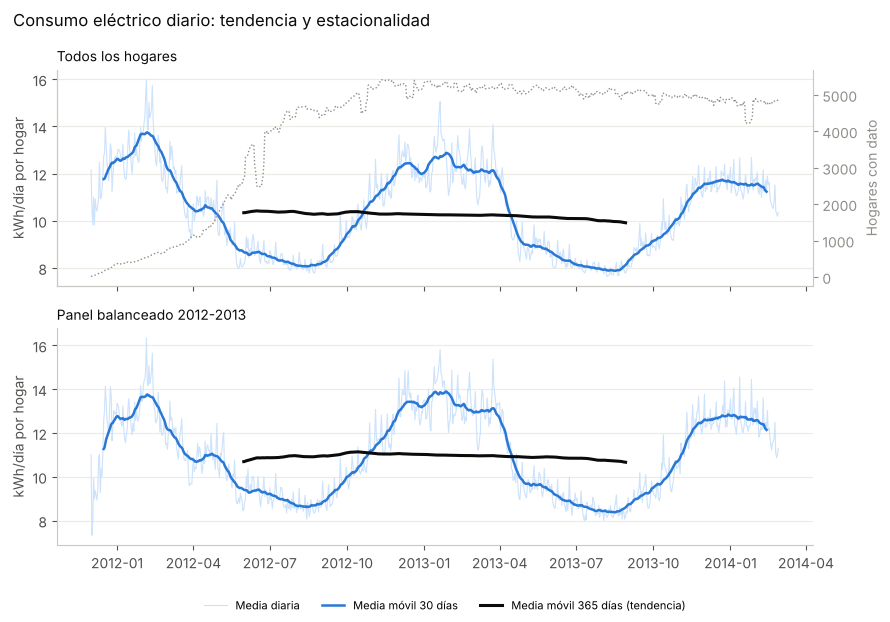

In [16]:
td = pd.read_csv(S / 'tendencia_diaria.csv', parse_dates=['fecha'])
fig, axs = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True)
for ax, suf, tit in [(axs[0], '', 'Todos los hogares'), (axs[1], '_panel', 'Panel balanceado 2012-2013')]:
    col = 'media_kwh' if suf == '' else 'media_panel'
    ax.plot(td.fecha, td[col], color='#cde2fb', lw=0.8, label='Media diaria')
    ax.plot(td.fecha, td['ma30' + suf], color=AZUL, lw=1.8, label='Media móvil 30 días')
    ax.plot(td.fecha, td['ma365' + suf], color=TINTA, lw=2.2, label='Media móvil 365 días (tendencia)')
    ax.set_ylabel('kWh/día por hogar'); ax.set_title(tit, color=TINTA, loc='left', fontsize=10)
    ax.grid(axis='y', color='#ecebe6')
ax2 = axs[0].twinx(); ax2.plot(td.fecha, td.hogares, color=GRIS, lw=1, ls=':')
ax2.set_ylabel('Hogares con dato', color=GRIS); ax2.spines['right'].set_visible(True); ax2.tick_params(axis='y', colors=GRIS)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, frameon=False, fontsize=8, ncol=3, loc='lower center')
fig.suptitle('Consumo eléctrico diario: tendencia y estacionalidad', x=0.02, ha='left', color=TINTA)
fig.tight_layout(rect=(0, 0.05, 1, 1)); guardar(fig, 'tendencia_serie_diaria.png'); plt.show()

**Por qué no basta una recta.** El programa ajusta también una recta de mínimos cuadrados sobre 2012 y 2013 (`pendiente_kwh_por_anio` y `r2_recta` en la tabla de abajo). Su R² es muy bajo porque la estacionalidad anual concentra casi toda la variabilidad. Por eso la media móvil de 365 días es la medida adecuada de la tendencia.

In [17]:
res_t[['pendiente_kwh_por_anio', 'pendiente_pct_por_anio', 'r2_recta']].round(3)

,pendiente_kwh_por_anio,pendiente_pct_por_anio,r2_recta
serie,,,
todos,-0.706,-6.883,0.048
panel,-0.443,-4.076,0.018


---
# 5. Estacionalidad semanal y anual (informe 12.c)

## 5.1 Método: descomposición clásica multiplicativa

Se supone que la serie es el producto de una tendencia y un factor estacional, $\bar{y}_d = T_d \times E_d \times \varepsilon_d$:

1. **Tendencia local:** la media móvil centrada de 7 días, $MA_7(d)$, elimina el ciclo semanal.
2. **Cociente estacional:** $\bar{y}_d / MA_7(d)$ indica cuánto se desvía cada día de su semana.
3. **Índice semanal:** el promedio de esos cocientes por día de la semana, normalizado para que promedie 1. Un índice de 1.05 significa un 5 % sobre el promedio semanal.
4. **Índice mensual:** la media de cada mes dividida entre la media de 2012 y 2013.

## 5.2 Índices calculados

In [18]:
sem = pd.read_csv(S / 'indice_semanal.csv'); men = pd.read_csv(S / 'indice_mensual.csv')
meses = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Set','Oct','Nov','Dic']
men['mes_nombre'] = men.mes.map(lambda m: meses[m - 1])
display(sem.pivot(index='dia', columns='serie', values='indice').loc[sem.dia.unique()].round(3))
men[men.serie == 'todos'][['mes_nombre', 'media_2012', 'media_2013', 'var_interanual_pct', 'indice']].round(3)

serie,panel,todos
dia,,
lunes,1.003,1.001
martes,0.984,0.987
miércoles,0.975,0.985
jueves,0.978,0.981
viernes,0.992,0.984
sábado,1.004,1.008
domingo,1.065,1.055


,mes_nombre,media_2012,media_2013,var_interanual_pct,indice
0,Ene,12.814,12.630,-1.436,1.241
1,Feb,13.407,12.352,-7.870,1.258
2,Mar,11.242,12.087,7.515,1.138
3,Abr,10.632,10.058,-5.403,1.009
4,May,9.122,8.903,-2.403,0.879
5,Jun,8.665,8.341,-3.738,0.830
6,Jul,8.316,8.041,-3.308,0.798
7,Ago,8.079,7.884,-2.420,0.779
8,Set,8.730,8.765,0.397,0.854
9,Oct,10.109,9.511,-5.910,0.957


## 5.3 Figura 12.2 — Índice semanal y comparación mensual 2012 frente a 2013

Ambos paneles usan el **panel balanceado**, para que la comparación entre años no dependa de la composición. Las barras azul oscuro del panel izquierdo marcan los días sobre el promedio.

Figura guardada en resultados_series/tendencia_indices.png


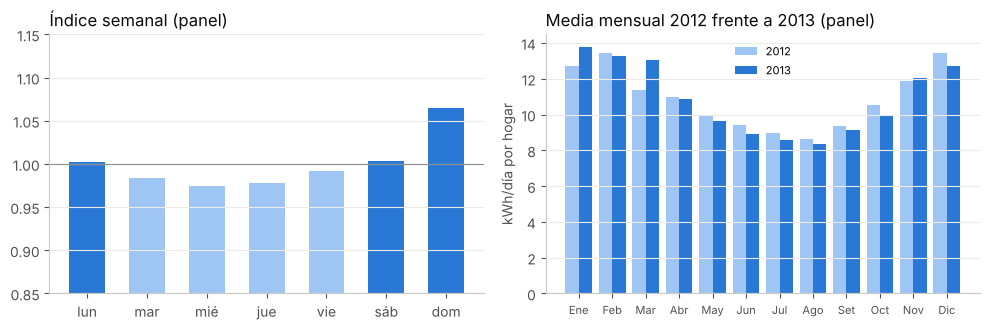

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
g = sem[sem.serie == 'panel']
axs[0].bar(g.dia.str[:3], g.indice, color=[AZUL if v > 1 else AZUL_CLARO for v in g.indice], width=0.6)
axs[0].axhline(1, color=GRIS, lw=0.8); axs[0].set_ylim(0.85, 1.15)
axs[0].set_title('Índice semanal (panel)', color=TINTA, loc='left'); axs[0].grid(axis='y', color='#ecebe6')
g = men[men.serie == 'panel']; x = np.arange(12)
axs[1].bar(x - 0.2, g.media_2012, 0.4, color=AZUL_CLARO, label='2012')
axs[1].bar(x + 0.2, g.media_2013, 0.4, color=AZUL, label='2013')
axs[1].set_xticks(x); axs[1].set_xticklabels(meses, fontsize=8); axs[1].set_ylabel('kWh/día por hogar')
axs[1].set_title('Media mensual 2012 frente a 2013 (panel)', color=TINTA, loc='left')
axs[1].grid(axis='y', color='#ecebe6'); axs[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); guardar(fig, 'tendencia_indices.png'); plt.show()

**Lectura:**
- **Semanal:** el pico se concentra en el **domingo**, no en todo el fin de semana. La variable `is_weekend` trata igual al sábado y al domingo, lo que es una limitación del modelo.
- **Anual:** es la componente dominante, con invierno (calefacción e iluminación) muy por encima del verano.
- **Interanual:** si la mayoría de meses de 2013 están por debajo de 2012, se confirma la tendencia decreciente. Las excepciones, como marzo de 2013, que fue excepcionalmente frío en el Reino Unido, muestran el efecto del clima, que el modelo no incorpora.

---
# 6. Evaluación del modelo como pronóstico (informe 12.d)

## 6.1 Planteamiento

Hasta la PC2 el modelo se evaluó como una regresión (R² en validación). Ahora se evalúa como un **pronóstico a un día**:

1. **Ajuste** con train + validation: todo lo anterior al **1 de enero de 2014**.
2. **Pronóstico** de cada día del **conjunto de prueba** (enero y febrero de 2014), reservado desde la PC1, usando solo la información disponible hasta el día anterior.
3. **Comparación** con reglas que no requieren entrenamiento. Un modelo de pronóstico solo aporta valor si las supera:

| Regla de referencia | Pronóstico de $y_t$ | Columna usada |
|---|---|---|
| Ingenuo | $y_{t-1}$: «hoy igual que ayer» | `lag_1_kwh` |
| Ingenuo estacional | $y_{t-7}$: «igual que el mismo día de la semana pasada» | `lag_7_kwh` |
| Media móvil | promedio de los 7 días previos | `rolling_mean_7_kwh` |

**Métricas:**
- **RMSE** y **MAE:** error en kWh/día; el RMSE castiga más los errores grandes.
- **R²:** proporción de la variabilidad que se explica.
- **sMAPE:** error porcentual simétrico, $\frac{200}{n}\sum \frac{|y - \hat{y}|}{|y| + |\hat{y}|}$. Se prefiere al MAPE porque hay días con consumo cero.

Las columnas `lag_*` se construyeron con el consumo **winsorizado**, el mismo objetivo del modelo, así que la comparación es justa.

In [20]:
!./series/series -input {DATA} -mode pronostico -outdir resultados_series | tee resultados_series/ejecucion_pronostico.txt

CPU lógicas: 2 | GOMAXPROCS: 2 | Go go1.24.7


Filas: 3285438 (train 2559364 | validation 452163 | test 273911) | hogares: 5559 | 2011-12-01 a 2014-02-27 | carga: 13.173s



=== PRONÓSTICO A UN DÍA SOBRE TEST (2014-01-01 a 2014-02-27) ===
Ajuste con train+validation: 3011527 filas | Test: 273911 filas



Predictor                      RMSE      MAE   sMAPE %       R2 Mejora RMSE vs lag_7
ARX (regresión)              3.4678   2.0737     20.88   0.8773 +30.2 %
Ingenuo: lag_1 (ayer)        4.0508   2.4039     21.89   0.8325 +18.5 %
Ingenuo estacional: lag_7    4.9715   2.7464     25.13   0.7477 +0.0 %
Media móvil 7 días           3.6957   2.1337     20.23   0.8606 +25.7 %



Residuos [ajuste] n=3011527 | media -0.0000 | Durbin-Watson 2.043 | ACF(1) -0.022 | ACF(7) -0.031



Residuos [test] n=273911 | media -0.0679 | Durbin-Watson 2.155 | ACF(1) -0.069 | ACF(7) 0.002


## 6.2 Tabla del informe: modelo frente a reglas ingenuas

In [21]:
pron = pd.read_csv(S / 'pronostico_test.csv')
pron['mejora_rmse_vs_ingenuo_pct'] = 100 * (1 - pron.rmse.iloc[0] / pron.rmse)
pron.round(3)

,predictor,n,rmse,mae,smape_pct,r2,mejora_rmse_vs_naive_estacional_pct,mejora_rmse_vs_ingenuo_pct
0,ARX (regresión),273911,3.468,2.074,20.884,0.877,30.246,0.000
1,Ingenuo: lag_1 (ayer),273911,4.051,2.404,21.895,0.832,18.518,14.392
2,Ingenuo estacional: lag_7,273911,4.972,2.746,25.129,0.748,0.000,30.246
3,Media móvil 7 días,273911,3.696,2.134,20.232,0.861,25.662,6.167


**Lectura:**
- `mejora_rmse_vs_naive_estacional_pct` es la reducción del error de cada predictor respecto de «igual que la semana pasada».
- `mejora_rmse_vs_ingenuo_pct` indica cuánto mejor es el modelo que cada regla; por eso vale 0 en la fila del modelo.
- El R² de prueba puede superar al de validación (0.8618) sin que el modelo sea «mejor»: en invierno la variabilidad entre hogares es mayor, y el R² es una proporción de esa variabilidad.

## 6.3 Figura 12.3 — Pronóstico en el conjunto de prueba para tres hogares

Se eligen los tres hogares con más días en el conjunto de prueba. La figura compara el consumo real (negro), el pronóstico del modelo (azul) y el ingenuo estacional (gris).

Figura guardada en resultados_series/pronostico_muestra.png


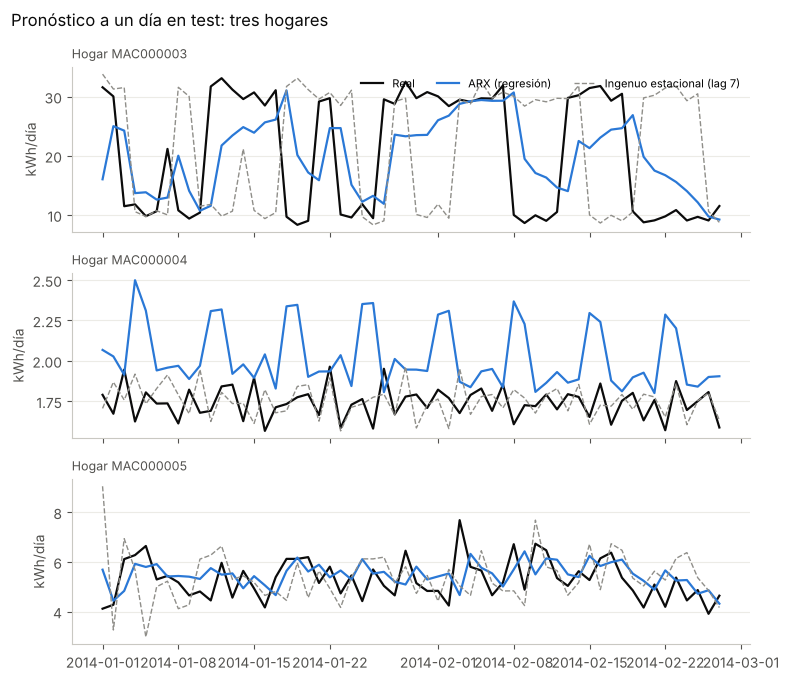

In [22]:
mu = pd.read_csv(S / 'pronostico_muestra.csv', parse_dates=['fecha'])
hogares = mu.hogar.unique()
fig, axs = plt.subplots(len(hogares), 1, figsize=(8, 2.3 * len(hogares)), sharex=True)
for ax, h in zip(np.atleast_1d(axs), hogares):
    g = mu[mu.hogar == h]
    ax.plot(g.fecha, g.real, color=TINTA, lw=1.6, label='Real')
    ax.plot(g.fecha, g.arx, color=AZUL, lw=1.6, label='ARX (regresión)')
    ax.plot(g.fecha, g.naive_lag7, color=GRIS, lw=1, ls='--', label='Ingenuo estacional (lag 7)')
    ax.set_ylabel('kWh/día'); ax.set_title(f'Hogar {h}', color=TINTA2, loc='left', fontsize=9)
    ax.grid(axis='y', color='#ecebe6')
np.atleast_1d(axs)[0].legend(frameon=False, ncol=3, fontsize=8, loc='upper right')
fig.suptitle('Pronóstico a un día en test: tres hogares', x=0.02, ha='left', color=TINTA)
fig.tight_layout(); guardar(fig, 'pronostico_muestra.png'); plt.show()

---
# 7. Diagnóstico de los residuos (informe 12.e)

## 7.1 Idea

Si el modelo aprovechó toda la información temporal, sus **errores no deberían repetirse** de un día a otro. Se mide con dos herramientas:

| Herramienta | Fórmula | Interpretación |
|---|---|---|
| **ACF** (autocorrelación) en el rezago *k* | correlación entre $e_t$ y $e_{t-k}$, **del mismo hogar**, separados exactamente *k* días | Cercana a 0: sin patrón. Pico en *k* = 7: estacionalidad semanal no capturada |
| **Durbin-Watson** | $DW = \sum (e_t - e_{t-1})^2 / \sum e_t^2$ | ≈ 2: sin autocorrelación. < 2: los errores persisten. > 2: se alternan |

**Importante:** con cientos de miles de pares, la banda de significancia del 95 % ($\pm 1.96/\sqrt{n}$) es muy estrecha y casi cualquier valor resulta «significativo». Por eso se juzga la **magnitud**: valores con $|ACF| < 0.1$ se consideran despreciables.

Los residuos se calcularon en la ejecución de la sección 6, en el ajuste (dentro de la muestra) y en el conjunto de prueba (fuera de ella).

In [23]:
diag = pd.read_csv(S / 'diagnostico_residuos.csv'); display(diag.round(4))
acf = pd.read_csv(S / 'acf_residuos.csv')
print('Máximo |ACF| en test:', acf[acf.conjunto == 'test'].acf.abs().max().round(4))

,conjunto,n,media_residuo,durbin_watson,acf_1,acf_7,acf_14
0,ajuste,3011527,-0.0000,2.0427,-0.0220,-0.0306,0.0747
1,test,273911,-0.0679,2.1553,-0.0686,0.0023,0.0838


Máximo |ACF| en test: 0.0838


## 7.2 Figura 12.4 — Autocorrelación de los residuos (la banda sombreada es el intervalo de 95 %)

Figura guardada en resultados_series/acf_residuos.png


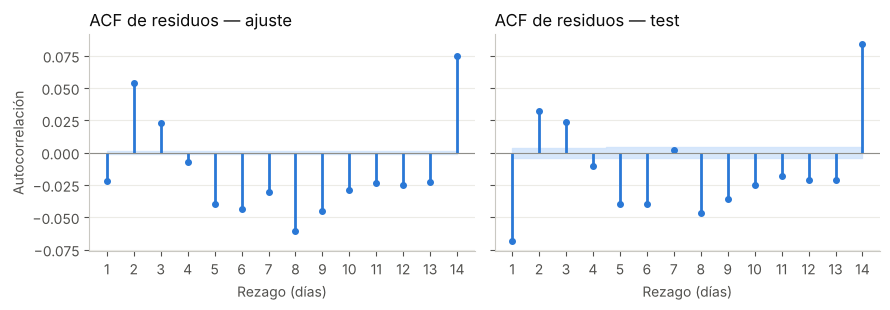

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (c, g) in zip(axs, acf.groupby('conjunto', sort=False)):
    ax.vlines(g.lag, 0, g.acf, color=AZUL, lw=2); ax.plot(g.lag, g.acf, 'o', color=AZUL, ms=4)
    ax.fill_between(g.lag, -g.banda_95, g.banda_95, color='#cde2fb', alpha=0.8, step='mid')
    ax.axhline(0, color=GRIS, lw=0.8); ax.set_xticks(range(1, int(g.lag.max()) + 1))
    ax.set_title(f'ACF de residuos — {c}', color=TINTA, loc='left'); ax.set_xlabel('Rezago (días)')
    ax.grid(axis='y', color='#ecebe6')
axs[0].set_ylabel('Autocorrelación')
fig.tight_layout(); guardar(fig, 'acf_residuos.png'); plt.show()

**Lectura:**
- **Durbin-Watson algo mayor que 2 y ACF(1) negativa:** el modelo reacciona algo de más al consumo de ayer. Si sobrestima un día, tiende a subestimar el siguiente.
- **Pequeño pico en el rezago 14:** sugiere un patrón quincenal residual.
- **Todas las autocorrelaciones bajo 0.1:** no queda estructura temporal relevante.
- **Residuo medio negativo en test:** el modelo sobrestima levemente 2014, lo que es coherente con la tendencia decreciente de la sección 4.

---
# 8. Validación walk-forward y su ejecución concurrente (informe 12.f)

## 8.1 Qué es el walk-forward

Una sola división entre entrenamiento y validación evalúa el modelo en **un** trimestre. El walk-forward (origen móvil con **ventana expansiva**) lo evalúa a lo largo de todo el periodo:

```
mes 2012-07:  entrenar [inicio ........ jun-2012]  → pronosticar jul-2012
mes 2012-08:  entrenar [inicio ......... jul-2012] → pronosticar ago-2012
   ...
mes 2014-02:  entrenar [inicio ............................ ene-2014] → pronosticar feb-2014
```

Son **20 meses** y cada uno es un **ajuste completo e independiente**, así que se pueden repartir entre goroutines.

## 8.2 Versión concurrente

`walkConcurrente` usa el mismo protocolo:
- un canal de meses;
- W workers;
- cada worker escribe el resultado de su mes en **su propia posición** `res[f.ID]`, que no requiere mutex;
- el acumulador global de errores se protege con `sync.Mutex`;
- `sync.WaitGroup` espera a todos los workers.

El programa ejecuta ambas versiones y **verifica que den exactamente el mismo resultado**.

In [25]:
!./series/series -input {DATA} -mode walkforward -desde 2012-07 -workers 2 -orden desc -outdir resultados_series | tee resultados_series/ejecucion_walkforward.txt

CPU lógicas: 2 | GOMAXPROCS: 2 | Go go1.24.7


Filas: 3285438 (train 2559364 | validation 452163 | test 273911) | hogares: 5559 | 2011-12-01 a 2014-02-27 | carga: 12.632s



=== WALK-FORWARD MENSUAL (20 meses, desde 2012-07) ===
Secuencial: 3096.9 ms | Concurrente (2 workers, orden desc): 1549.3 ms | speedup 2.00x
Diferencia máxima de SSE entre versiones: 0.00e+00 | RMSE global sec 3.2738 / conc 3.2738

Mes         Entrenam.     Filas  RMSE ARX RMSE lag7    R2 ARX
2012-07        270264    131410    2.5560    3.5300    0.8398
2012-08        401674    142384    2.4287    3.4874    0.8457
2012-09        544058    138405    2.7384    3.8210    0.8480
2012-10        682463    152094    3.1795    4.3058    0.8578
2012-11        834557    159731    3.4962    4.7649    0.8763
2012-12        994288    159809    4.1843    6.0202    0.8640
2013-01       1154097    164060    3.9948    6.1141    0.8838
2013-02       1318157    145660    3.9846    5.7295    0.8819
2013-03       1463817    160806    4.0601    5.9369    0.8749
2013-04       1624623    154943    3.4045    5.3529    0.8522
2013-05       1779566    159924    2.9058    3.9996    0.8371
2013-06       1939490 

## 8.3 Error mes a mes

In [26]:
wfm = pd.read_csv(S / 'walkforward_meses.csv')
wfm['modelo_supera_lag7'] = wfm.rmse_arx < wfm.rmse_naive_lag7
display(wfm.round(4))
print(f"El modelo supera al ingenuo estacional en {wfm.modelo_supera_lag7.sum()} de {len(wfm)} meses")

,mes,filas_entrenamiento,filas_mes,rmse_arx,rmse_naive_lag1,rmse_naive_lag7,rmse_media7,mae_arx,smape_arx,r2_arx,modelo_supera_lag7
0,2012-07,270264,131410,2.5560,2.9737,3.5300,2.6878,1.5640,20.5364,0.8398,True
1,2012-08,401674,142384,2.4287,2.7628,3.4874,2.6043,1.4772,20.1520,0.8457,True
2,2012-09,544058,138405,2.7384,3.1343,3.8210,2.9055,1.6472,20.9521,0.8480,True
3,2012-10,682463,152094,3.1795,3.6979,4.3058,3.3632,1.9357,21.3791,0.8578,True
4,2012-11,834557,159731,3.4962,4.1113,4.7649,3.6572,2.1286,21.1239,0.8763,True
5,2012-12,994288,159809,4.1843,4.7148,6.0202,4.5547,2.5052,23.7202,0.8640,True
6,2013-01,1154097,164060,3.9948,4.4409,6.1141,4.3640,2.3383,21.0441,0.8838,True
7,2013-02,1318157,145660,3.9846,4.5319,5.7295,4.3123,2.3275,21.2529,0.8819,True
8,2013-03,1463817,160806,4.0601,4.5483,5.9369,4.5106,2.3525,22.0023,0.8749,True
9,2013-04,1624623,154943,3.4045,3.8588,5.3529,3.7944,2.0213,22.1251,0.8522,True


El modelo supera al ingenuo estacional en 20 de 20 meses


## 8.4 Figura 12.5 — Error de pronóstico mes a mes

Figura guardada en resultados_series/walkforward_rmse_mensual.png


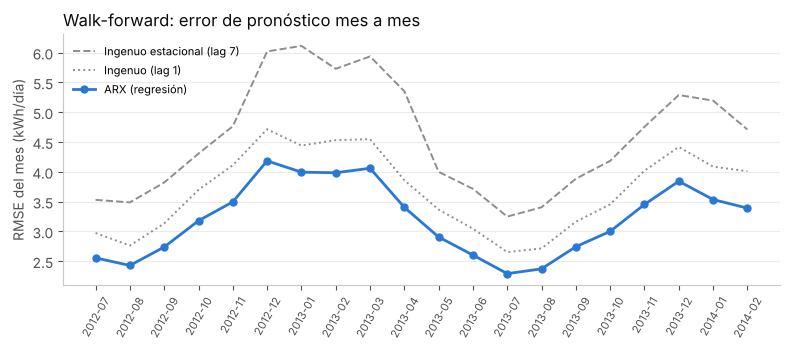

In [27]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(wfm))
ax.plot(x, wfm.rmse_naive_lag7, '--', color=GRIS, lw=1.4, label='Ingenuo estacional (lag 7)')
ax.plot(x, wfm.rmse_naive_lag1, ':', color=GRIS, lw=1.4, label='Ingenuo (lag 1)')
ax.plot(x, wfm.rmse_arx, '-o', color=AZUL, lw=2, ms=5, label='ARX (regresión)')
ax.set_xticks(x); ax.set_xticklabels(wfm.mes, rotation=60, fontsize=8)
ax.set_ylabel('RMSE del mes (kWh/día)')
ax.set_title('Walk-forward: error de pronóstico mes a mes', color=TINTA, loc='left')
ax.grid(axis='y', color='#ecebe6'); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); guardar(fig, 'walkforward_rmse_mensual.png'); plt.show()

**Lectura:** el error sube en invierno y baja en verano, siguiendo el nivel de consumo. Los errores son **heterocedásticos**, es decir, crecen con el nivel. En cambio, el R² se mantiene estable, lo que indica que la relación aprendida no se deteriora con el tiempo.

## 8.5 Balanceo de carga: orden de reparto

Los meses **no cuestan lo mismo**: el último entrena con unos 3.2 millones de filas y el primero con 0.27 millones. Si el mes más pesado se asigna al final, los demás workers terminan y quedan ociosos esperándolo. Se comparan dos órdenes de envío a la cola:

| Orden | Descripción |
|---|---|
| `asc` | Cronológico: del mes más liviano al más pesado |
| `desc` | **LPT** (*Longest Processing Time first*): los más pesados primero; es la misma idea de reparto *greedy* de Klawohn et al. (2023) |

Se usa el mismo protocolo de medición, con 10 repeticiones por configuración.

In [28]:
!./series/series -input {DATA} -mode benchmark -reps 10 -wlist 1,2,4 -orden desc -outdir resultados_series
!./series/series -input {DATA} -mode benchmark -reps 10 -wlist 1,2,4 -orden asc  -outdir resultados_series

CPU lógicas: 2 | GOMAXPROCS: 2 | Go go1.24.7


Filas: 3285438 (train 2559364 | validation 452163 | test 273911) | hogares: 5559 | 2011-12-01 a 2014-02-27 | carga: 14.361s

=== BENCHMARK WALK-FORWARD (20 meses, 10 repeticiones + 1 de calentamiento) ===


secuencial  workers=0   media recortada 10% =   3157.59 ms


concurrente workers=1   media recortada 10% =   3114.73 ms


concurrente workers=2   media recortada 10% =   1560.54 ms


...

Filas: 3285438 (train 2559364 | validation 452163 | test 273911) | hogares: 5559 | 2011-12-01 a 2014-02-27 | carga: 12.571s

=== BENCHMARK WALK-FORWARD (20 meses, 10 repeticiones + 1 de calentamiento) ===


secuencial  workers=0   media recortada 10% =   3142.47 ms


concurrente workers=1   media recortada 10% =   3156.97 ms


concurrente workers=2   media recortada 10% =   1663.95 ms


concurrente workers=4   media recortada 10% =   1754.57 ms


## 8.6 Tabla del informe: speedup por orden de reparto

In [29]:
filas = []
for orden in ['asc', 'desc']:
    r = pd.read_csv(S / f'walkforward_benchmark_{orden}.csv')
    g = r.groupby('workers').wall_ms.agg(lambda w: stats.trim_mean(w, 0.10))
    for w, t in g.items():
        filas.append({'orden': orden, 'workers': w, 'media_recortada_ms': t, 'speedup': g.loc[0] / t})
tab_f = pd.DataFrame(filas)
tab_f_pivot = tab_f[tab_f.workers > 0].pivot(index='workers', columns='orden', values='speedup')
tab_f_pivot.columns = ['speedup_cronologico', 'speedup_LPT']
tab_f.to_csv(S / 'tabla_12f_walkforward.csv', index=False)
costo = wfm.filas_entrenamiento + wfm.filas_mes
print(f"Tiempo secuencial (media recortada): {tab_f[(tab_f.orden=='desc') & (tab_f.workers==0)].media_recortada_ms.iloc[0]:,.0f} ms")
print(f"Cota de speedup por granularidad = suma de costos / mes más costoso = {costo.sum() / costo.max():.1f}x")
tab_f_pivot.round(3)

Tiempo secuencial (media recortada): 3,158 ms
Cota de speedup por granularidad = suma de costos / mes más costoso = 11.3x


,speedup_cronologico,speedup_LPT
workers,,
1,0.995,1.014
2,1.889,2.023
4,1.791,1.817


**Cota por granularidad.** El tiempo concurrente nunca puede ser menor que el del mes más costoso. Por eso el speedup del walk-forward no puede superar la cota calculada arriba, aunque se agreguen núcleos. Es el *trade-off* de granularidad: pocas tareas grandes reducen la sincronización, pero limitan el balanceo de carga.

---
# 9. Análisis comparativo del tiempo de ejecución (informe 12.g)

Para comparar en **igualdad de condiciones**, la construcción de $X^\top X$ de la PC2 se vuelve a medir en este mismo entorno, con el código del repositorio (`regresion/`). Se clona el repositorio público del grupo y se ejecuta su benchmark con 1 y 2 workers.

In [30]:
!rm -rf repo_tp && git clone -q https://github.com/MapleSyrup63/Programaci-nConcurrenteYDistribuida_TP_Grupo4 repo_tp
!cd repo_tp/regresion && go build -o regresion . && ./regresion -mode benchmark -input {DATA} -workerlist 1,2 -repeats 20 -trim 0.1 | tail -3
!cp repo_tp/regresion/benchmark_summary.csv resultados_series/regresion_xtx_benchmark.csv


Guardado: benchmark_raw.csv
Guardado: benchmark_summary.csv


## 9.1 Tabla del informe: las tres tareas

In [31]:
xtx = pd.read_csv(S / 'regresion_xtx_benchmark.csv').set_index('workers')
agg = tab_agg.set_index('workers')
wf = tab_f[tab_f.orden == 'desc'].set_index('workers')
tab_g = pd.DataFrame([
    ['Construcción de XᵀX y Xᵀy', xtx.loc[0, 'media_recortada_ms'], '78 multiplicaciones', xtx.loc[1, 'speedup'], xtx.loc[2, 'speedup']],
    ['Agregación de la serie diaria', agg.loc[0, 'media_recortada_ms'], '1 suma y 1 conteo', agg.loc[1, 'speedup'], agg.loc[2, 'speedup']],
    ['Walk-forward mensual (orden LPT)', wf.loc[0, 'media_recortada_ms'], '20 ajustes completos', wf.loc[1, 'speedup'], wf.loc[2, 'speedup']],
], columns=['tarea', 'tiempo_secuencial_ms', 'trabajo_por_fila', 'speedup_1_worker', 'speedup_2_workers'])
tab_g.to_csv(S / 'tabla_12g_comparacion.csv', index=False)
tab_g.round(2)

,tarea,tiempo_secuencial_ms,trabajo_por_fila,speedup_1_worker,speedup_2_workers
0,Construcción de XᵀX y Xᵀy,337.88,78 multiplicaciones,0.98,1.95
1,Agregación de la serie diaria,11.43,1 suma y 1 conteo,0.92,1.82
2,Walk-forward mensual (orden LPT),3157.59,20 ajustes completos,1.01,2.02


**Lectura:** las tres tareas usan el mismo patrón de sincronización, pero no se benefician por igual:
- las que tienen **suficiente trabajo** (XᵀX y walk-forward) llegan cerca de 2x y no pierden rendimiento con 1 worker;
- la **agregación** dura tan poco que los costos fijos de la concurrencia pesan.

La conveniencia de la concurrencia depende de la **cantidad de trabajo por tarea**, no solo del volumen de datos. Las 78 multiplicaciones de XᵀX salen de que la matriz es simétrica de 12×12: se calcula solo el triángulo superior, 12·13/2 = 78 productos por fila.

---
# 10. Detector de carreras

Spin verifica el **modelo** del protocolo (sección 13 del informe). `go run -race` verifica el **código real**: instrumenta cada acceso a memoria y reporta `DATA RACE` si dos goroutines acceden a la misma variable sin sincronización. Como el detector hace la ejecución unas 10 veces más lenta, se limita el walk-forward a los meses desde julio de 2013.

In [32]:
!cd series && go run -race . -input {DATA} -mode walkforward -desde 2013-07 -workers 4 -outdir ../resultados_series/race 2>&1 | tee ../resultados_series/race_detector.txt | grep -E "speedup|Diferencia"
!cd series && go run -race . -input {DATA} -mode tendencia -reps 1 -wlist 4 -outdir ../resultados_series/race 2>&1 | tee -a ../resultados_series/race_detector.txt | grep -E "Conteos"
!grep -q "DATA RACE" resultados_series/race_detector.txt && echo "ATENCIÓN: se detectaron condiciones de carrera" || echo "Resultado: 0 condiciones de carrera detectadas"

Secuencial: 50121.4 ms | Concurrente (4 workers, orden desc): 27293.9 ms | speedup 1.84x
Diferencia máxima de SSE entre versiones: 0.00e+00 | RMSE global sec 3.1094 / conc 3.1094


Conteos idénticos; diferencia relativa máxima de sumas: 4.7e-15 (orden de suma en punto flotante)


Resultado: 0 condiciones de carrera detectadas


---
# 11. Cifras citadas en el informe (12.h)

Esta celda calcula, **desde los CSV generados**, cada cifra que cita la sección 12 del informe. Si se vuelve a ejecutar el cuaderno en otro equipo (por ejemplo, la PC de 8 núcleos), basta con copiar estas cifras al informe. Las del modelo no cambiarán; las de tiempo, sí.

In [33]:
P = pron.set_index('predictor')
arx, ing, est, mm = P.index[0], P.index[1], P.index[2], P.index[3]
d_test = diag.set_index('conjunto').loc['test']
a_test = acf[acf.conjunto == 'test'].set_index('lag').acf
indm = men[men.serie == 'todos'].set_index('mes_nombre')
inds = sem[sem.serie == 'todos'].set_index('dia').indice
peor, mejor = wfm.loc[wfm.rmse_arx.idxmax()], wfm.loc[wfm.rmse_arx.idxmin()]
lpt2 = tab_f_pivot.loc[2]

print('12.a  Agregación:', ', '.join(f"{r.configuracion} {r.media_recortada_ms:.2f} ms ({r.speedup:.2f}x)" for r in tab_agg.itertuples()),
      f"| CV máximo {tab_agg.CV_pct.max():.1f} %")
print(f"12.b  Todos: {res_t.loc['todos','media_2012']:.3f} → {res_t.loc['todos','media_2013']:.3f} kWh/día ({res_t.loc['todos','var_anual_pct']:+.2f} %)"
      f" | MA365 {res_t.loc['todos','var_ma365_pct']:+.2f} % | intra-hogar {intra.var_agregada_pct:+.2f} % ({int(intra.hogares):,} hogares)"
      f" | panel {res_t.loc['panel','var_anual_pct']:+.2f} % | recta {res_t.loc['todos','pendiente_kwh_por_anio']:+.2f} kWh/día/año, R² {res_t.loc['todos','r2_recta']:.3f}")
print(f"12.c  Índice semanal: domingo {inds['domingo']:.3f}, sábado {inds['sábado']:.3f}, lunes {inds['lunes']:.3f}, mar-vie {inds[['martes','miércoles','jueves','viernes']].min():.3f}-{inds[['martes','miércoles','jueves','viernes']].max():.3f}")
print(f"      Índice mensual: máx {indm.indice.idxmax()} {indm.indice.max():.3f}, mín {indm.indice.idxmin()} {indm.indice.min():.3f},"
      f" relación {indm.indice.max() / indm.indice.min():.2f} | meses con menos consumo en 2013: {(indm.var_interanual_pct < 0).sum()} de 12"
      f" | marzo {indm.loc['Mar','var_interanual_pct']:+.1f} %")
print(f"12.d  ARX: RMSE {P.loc[arx,'rmse']:.3f}, MAE {P.loc[arx,'mae']:.3f}, sMAPE {P.loc[arx,'smape_pct']:.2f} %, R² {P.loc[arx,'r2']:.3f}"
      f" | mejora vs ingenuo estacional {P.loc[arx,'mejora_rmse_vs_naive_estacional_pct']:.1f} %,"
      f" vs ingenuo {100 * (1 - P.loc[arx,'rmse'] / P.loc[ing,'rmse']):.1f} %, vs media móvil {100 * (1 - P.loc[arx,'rmse'] / P.loc[mm,'rmse']):.1f} %"
      f" | sMAPE media móvil {P.loc[mm,'smape_pct']:.2f} %")
print(f"12.e  Test: Durbin-Watson {d_test.durbin_watson:.3f}, ACF(1) {a_test[1]:.3f}, ACF(7) {a_test[7]:.3f}, ACF(14) {a_test[14]:.3f},"
      f" residuo medio {d_test.media_residuo:.3f} kWh/día, máx |ACF| {a_test.abs().max():.3f}")
print(f"12.f  Walk-forward: {len(wfm)} meses, modelo supera a lag 7 en {wfm.modelo_supera_lag7.sum()}; RMSE máx {peor.rmse_arx:.2f} ({peor.mes}),"
      f" mín {mejor.rmse_arx:.2f} ({mejor.mes}); R² {wfm.r2_arx.min():.3f}-{wfm.r2_arx.max():.3f}"
      f" | 2 workers: LPT {lpt2.speedup_LPT:.2f}x vs cronológico {lpt2.speedup_cronologico:.2f}x"
      f" ({100 * (lpt2.speedup_LPT / lpt2.speedup_cronologico - 1):+.1f} %) | cota {costo.sum() / costo.max():.1f}x")
print('12.g ', ' | '.join(f"{r.tarea}: {r.tiempo_secuencial_ms:,.2f} ms, {r.speedup_1_worker:.2f}x / {r.speedup_2_workers:.2f}x" for r in tab_g.itertuples()))

12.a  Agregación: Secuencial 11.43 ms (1.00x), Concurrente, 1 worker(s) 12.37 ms (0.92x), Concurrente, 2 worker(s) 6.30 ms (1.82x), Concurrente, 4 worker(s) 5.42 ms (2.11x), Concurrente, 8 worker(s) 5.45 ms (2.10x), Concurrente, 16 worker(s) 5.60 ms (2.04x) | CV máximo 10.0 %
12.b  Todos: 10.402 → 10.096 kWh/día (-2.93 %) | MA365 -4.12 % | intra-hogar -3.14 % (5,325 hogares) | panel -0.28 % | recta -0.71 kWh/día/año, R² 0.048
12.c  Índice semanal: domingo 1.055, sábado 1.008, lunes 1.001, mar-vie 0.981-0.987
      Índice mensual: máx Feb 1.258, mín Ago 0.779, relación 1.61 | meses con menos consumo en 2013: 10 de 12 | marzo +7.5 %
12.d  ARX: RMSE 3.468, MAE 2.074, sMAPE 20.88 %, R² 0.877 | mejora vs ingenuo estacional 30.2 %, vs ingenuo 14.4 %, vs media móvil 6.2 % | sMAPE media móvil 20.23 %
12.e  Test: Durbin-Watson 2.155, ACF(1) -0.069, ACF(7) 0.002, ACF(14) 0.084, residuo medio -0.068 kWh/día, máx |ACF| 0.084
12.f  Walk-forward: 20 meses, modelo supera a lag 7 en 20; RMSE máx 4.18 

---
# 12. Evidencias para el repositorio

Se empaqueta lo que debe subirse a GitHub, desde una rama de Git Flow, por ejemplo `feature/series-temporales`:

| Carpeta | Contenido |
|---|---|
| `series/` | Código Go del análisis |
| `resultados_series/` | Ejecuciones, CSV, tablas del informe y las 5 figuras |

El dataset **no** se sube, porque está en `.gitignore`.

In [34]:
!rm -rf entrega_series && mkdir -p entrega_series && cp -r series resultados_series entrega_series/ && rm -f entrega_series/series/series && rm -rf entrega_series/resultados_series/race
!cd entrega_series && zip -qr ../evidencias_series.zip . && cd .. && unzip -l evidencias_series.zip | tail -n +4 | head -45
try:
    from google.colab import files
    files.download('evidencias_series.zip')
except ImportError:
    print('Fuera de Colab: el archivo quedó en evidencias_series.zip')

        0  2026-10-09 23:56   series/
       23  2026-10-09 23:56   series/go.mod
    12872  2026-10-09 23:56   series/tendencia.go
    23705  2026-10-09 23:56   series/series.go
      345  2026-10-09 23:56   series/cpu_unix.go
      567  2026-10-09 23:56   series/cpu_windows.go
        0  2026-10-09 23:56   resultados_series/
      889  2026-10-09 23:56   resultados_series/acf_residuos.csv
     2264  2026-10-09 23:56   resultados_series/race_detector.txt
    83938  2026-10-09 23:56   resultados_series/acf_residuos.png
      309  2026-10-09 23:56   resultados_series/indice_semanal.csv
     2004  2026-10-09 23:56   resultados_series/walkforward_benchmark_desc.csv
     1707  2026-10-09 23:56   resultados_series/ejecucion_walkforward.txt
      328  2026-10-09 23:56   resultados_series/tabla_12b_tendencia.csv
      331  2026-10-09 23:56   resultados_series/pronostico_test.csv
      574  2026-10-09 23:56   resultados_series/tabla_12a_agregacion.csv
    81209  2026-10-09 23:56   resultados_s

Fuera de Colab: el archivo quedó en evidencias_series.zip
